# mini-vLLM, Part 2: Static Batching

**What we will build and measure**

[Stage 2](https://github.com/chizkidd/minivllm/blob/main/01_baseline_and_kv-cache.ipynb) ended with a prediction: 
>_batch-1 decode does about one FLOP per byte, far below the hardware ridge point, and each step is dominated by launch overhead. If that is right, serving several sequences at once should be nearly free, because every weight read is shared._

**Stage 3, static batching** tests that prediction and then looks at what it costs.

1. **Batch several sequences into one forward pass:** left-padding, an attention mask and per-sequence RoPE positions. Prove it is still correct before benchmarking.
2. **Measure the gain:** aggregate throughput, step latency and roofline position as the batch grows.
3. **Measure the waste:** padding in the prompt, idle slots when sequences finish at different times, and how long short requests wait for long ones.
4. **Measure the memory:** how much of the preallocated KV cache is actually used.

Those costs are exactly what Stage 4 (continuous batching) and Stage 5 (paged KV cache) remove.

**How to use this notebook.** Same shape as Part 1: *Goal, Concept, Code, Result, Takeaway*, with a prediction before every benchmark. The takeaways here are written as "how to read the result" because the numbers come from your run.

| # | Section | What we learn | Approx. runtime on a Kaggle T4 |
| --- | --- | --- | --- |
| 1 | Setup | Reproducible environment | seconds |
| 2 | The code | Batched forward pass, masks, a static-batching scheduler | seconds |
| 3 | Load model and correctness gate | Padded batches match one-at-a-time results | about 1 min |
| 4 | A. Batch-size scaling | What batching buys | about 1 min |
| 5 | A2. Roofline revisited | Why it buys that much | seconds |
| 6 | B. Padding waste | Cost of different prompt lengths | about 1 min |
| 7 | C. Idle decode slots | Cost of different output lengths | about 5 min |
| 8 | D. The latency hit | What short requests pay | seconds (reuses section 7 runs) |
| 9 | E. KV memory over-allocation | What preallocation wastes | seconds |
| 10 | Save results | JSON and figure inventory | seconds |
| 11 | Publish (optional) | Push results (and code, if this is the newest notebook) to GitHub | seconds |
| 12 | Summary | Findings and what comes next | seconds |

**Kaggle setup:** Accelerator = GPU T4 x2 (we use only the first GPU), Internet = On. Run top to bottom and restart the kernel before the final run. Set `QUICK = True` in the setup cell for a run of about 4 minutes instead of about 10.

**Self-contained.** Like Part 1, the `%%writefile` cells write the whole `minivllm/` and `bench/` packages and the notebook imports them. Files that did not change since Part 1 are repeated verbatim. `minivllm/model.py` gained two optional arguments, and `minivllm/batching.py`, `minivllm/scheduler.py` and `bench/workload.py` are new.

---
## 1. Setup

**Goal:** one imports cell, one environment record.

- `CUDA_VISIBLE_DEVICES=0` is set *before* importing torch, so "we only use one GPU" is enforced rather than assumed.
- `ENV` records GPU, torch, transformers and python versions, saved with the results.
- `SEED` fixes the synthetic workloads, so every batch size sees exactly the same requests.
- `QUICK = True` shrinks the sweeps (fewer batch sizes and requests) for a fast pass.
- - After editing a `%%writefile` cell, re-run it and then restart the kernel (or reload the module), because modules that were already imported keep their old code.

In [1]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle T4 x2: use one GPU only

import gc, platform

import numpy as np
import pandas as pd
import torch, transformers

for d in ("minivllm", "bench", "results"):
    os.makedirs(d, exist_ok=True)
for pkg in ("minivllm", "bench"):
    open(f"{pkg}/__init__.py", "a").close()

assert torch.cuda.is_available(), "Turn on a GPU accelerator in Kaggle settings"

QUICK = False   # True: fewer batch sizes and requests (about 4 minutes instead of about 10)
SEED = 0

ENV = {
    "gpu": torch.cuda.get_device_name(0),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "python": platform.python_version(),
}
print(ENV)

{'gpu': 'Tesla T4', 'torch': '2.10.0+cu128', 'transformers': '5.0.0', 'python': '3.12.13'}


---
## 2. The code

Four files are new or changed. Read them in this order: the model change, the batching helpers, the scheduler, then the benchmark helpers. The unchanged files from Part 1 follow at the end of this section.

### 2.1 What changes in the model (`minivllm/model.py`)

**Concept.** One forward pass over `B` sequences needs two things Part 1 did not have:

- **Per-sequence RoPE positions.** In Part 1 every token's position was "cache length plus its index". With padding, sequence A may start at column 4 and sequence B at column 0, but both must see their first real token at position 0. `forward` now takes an optional `positions` tensor of shape `[B, T]`, and gathers the cos/sin tables with it.
- **An attention mask.** Padding columns must never be attended to, and a token must not see the future. `forward` takes an optional boolean `attn_mask` of shape `[B, 1, T, L]` (`True` means "may attend"). With a mask, scaled dot-product attention gets `attn_mask=` instead of `is_causal=True`.

Both arguments default to `None`, which is exactly the Part 1 behaviour, so Stage 1 and 2 results reproduce.

**Why left padding?** `forward` returns the logits of the *last* position. If we padded on the right, the last column would be padding for the short sequences. Padding on the left keeps the last column a real token for everyone.

In [2]:
%%writefile minivllm/model.py
import torch
import torch.nn.functional as F

def rms_norm(x, weight, eps):
    xf = x.float()
    xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + eps)
    return weight * xf.to(x.dtype)

def rotate_half(x):
    h = x.shape[-1] // 2
    return torch.cat((-x[..., h:], x[..., :h]), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos + rotate_half(x) * sin

class MiniQwen:
    def __init__(self, hf_model, max_pos=2048):
        cfg = hf_model.config
        self.n_layers = cfg.num_hidden_layers
        self.n_heads = cfg.num_attention_heads
        self.n_kv = cfg.num_key_value_heads
        self.hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // self.n_heads
        self.n_rep = self.n_heads // self.n_kv
        self.eps = cfg.rms_norm_eps

        m = hf_model.model
        self.embed = m.embed_tokens.weight
        self.norm_w = m.norm.weight
        self.lm_head = hf_model.lm_head.weight
        self.device, self.dtype = self.embed.device, self.embed.dtype
        self.layers = []
        for l in m.layers:
            a, mlp = l.self_attn, l.mlp
            self.layers.append(dict(
                ln1=l.input_layernorm.weight, ln2=l.post_attention_layernorm.weight,
                q_w=a.q_proj.weight, q_b=a.q_proj.bias,
                k_w=a.k_proj.weight, k_b=a.k_proj.bias,
                v_w=a.v_proj.weight, v_b=a.v_proj.bias,
                o_w=a.o_proj.weight,
                gate=mlp.gate_proj.weight, up=mlp.up_proj.weight, down=mlp.down_proj.weight,
            ))

        theta = getattr(cfg, "rope_theta", None)
        if theta is None:
            theta = cfg.rope_parameters["rope_theta"]
        inv = 1.0 / (theta ** (torch.arange(0, self.hd, 2, device=self.device).float() / self.hd))
        t = torch.arange(max_pos, device=self.device).float()
        emb = torch.cat([torch.outer(t, inv)] * 2, dim=-1)
        self.cos, self.sin = emb.cos().to(self.dtype), emb.sin().to(self.dtype)

    @torch.no_grad()
    def forward(self, ids, cache=None, positions=None, attn_mask=None):
        """
        ids: [B, T]. Returns logits for the LAST position only: [B, vocab].
        Batching of sequences with different lengths (Stage 3) adds two optional inputs:
          positions: [B, T] RoPE position of every token (default: consecutive from the cache length).
          attn_mask: bool [B, 1, T, L], True = this query may attend to this key, where L is the
                     number of keys after the cache update (default: causal, no padding).
        """
        B, T = ids.shape
        pos0 = cache.length if cache is not None else 0
        assert not (cache is not None and T > 1 and pos0 > 0), "prefill only from an empty cache"
        if positions is None:
            assert pos0 + T <= self.cos.shape[0], "sequence longer than RoPE table"
            cos = self.cos[pos0:pos0 + T][None, None]
            sin = self.sin[pos0:pos0 + T][None, None]
        else:
            cos = self.cos[positions][:, None]   # [B, 1, T, head_dim]
            sin = self.sin[positions][:, None]

        x = F.embedding(ids, self.embed)
        for i, L in enumerate(self.layers):
            h = rms_norm(x, L["ln1"], self.eps)
            q = F.linear(h, L["q_w"], L["q_b"]).view(B, T, self.n_heads, self.hd).transpose(1, 2)
            k = F.linear(h, L["k_w"], L["k_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            v = F.linear(h, L["v_w"], L["v_b"]).view(B, T, self.n_kv, self.hd).transpose(1, 2)
            q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
            if cache is not None:
                k, v = cache.update(i, k, v)
            # Expand KV heads to match query heads (GQA). Wasteful, a known optimization target.
            k = k.repeat_interleave(self.n_rep, dim=1)
            v = v.repeat_interleave(self.n_rep, dim=1)
            a = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                               is_causal=(attn_mask is None and T > 1))
            a = a.transpose(1, 2).reshape(B, T, -1)
            x = x + F.linear(a, L["o_w"])
            h = rms_norm(x, L["ln2"], self.eps)
            x = x + F.linear(F.silu(F.linear(h, L["gate"])) * F.linear(h, L["up"]), L["down"])
        if cache is not None:
            cache.advance(T)
        x = rms_norm(x[:, -1], self.norm_w, self.eps)
        return F.linear(x, self.lm_head)

Writing minivllm/model.py


### 2.2 Padding, positions and masks (`minivllm/batching.py`)

**Concept.** `left_pad` stacks token lists into one rectangle. `Layout` builds the positions and masks for one batch:

```
column:   0 1 2 3 4 5 | 6 7 8 ...      T = longest prompt, generated tokens follow
seq A:    . . A A A A | g g g          (. = padding, A = prompt token, g = generated)
seq B:    . B B B B B | g g g
```

All sequences share the same cache columns, so the KV cache stays one rectangle. Padding columns are masked out, and positions count only real tokens.

**A bug worth remembering.** A *padding* query row has no real key to attend to (everything it could see is padding). A fully masked row makes the softmax produce NaN, and since `0 * NaN = NaN`, one such row can poison the real tokens that read its values. The fix is one line: let every row attend to at least itself. Its output is garbage, but it is finite, and nobody reads it.

In [3]:
%%writefile minivllm/batching.py
import torch

def left_pad(seqs, pad_id, device, pad_to=None):
    """
    Stack variable-length token lists into one [B, T] tensor, padding on the LEFT so that the
    last column is a real token for every sequence (generation reads the last position).
    Returns (ids [B, T], lens [B]) where lens are the real prompt lengths. `pad_to` forces a
    longer T than the longest prompt (e.g. to round up to a multiple of 8). 
    
    If you use `pad_to`, build the matching `Layout(..., T=ids.shape[1])` too: Layout assumes 
    the longest prompt otherwise, and its positions and masks would not fit the tensor.
    """
    lens = [len(s) for s in seqs]
    T = max(lens + [pad_to or 0])
    ids = torch.full((len(seqs), T), pad_id, dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, T - len(s):] = torch.as_tensor(s, dtype=torch.long)
    return ids.to(device), torch.tensor(lens, device=device)

class Layout:
    """
    Positions and attention masks for one wave of left-padded sequences.
    
      column:   0 1 2 3 4 5 | 6 7 8 ...      T = longest prompt, then generated tokens follow
      seq A:    . . A A A A | g g g          (. = padding, A = prompt token, g = generated)
      seq B:    . B B B B B | g g g
    
    Every sequence shares the same cache columns, so the cache stays a single rectangle. Padding
    columns are never attended to, and RoPE positions count only real tokens (A starts at 0).
    """                                                                         
    def __init__(self, lens, max_new, device, T=None):
        self.lens = lens.to(device)                         # [B] real prompt lengths
        self.T = T or int(self.lens.max())                  # padded prompt length (columns)
        self.device = device
        self.pad = self.T - self.lens                       # [B] padding columns per sequence
        cols = torch.arange(self.T + max_new, device=device)
        self.key_real = cols[None, :] >= self.pad[:, None]  # [B, T + max_new]: True on real tokens

    def prefill(self):
        """positions [B, T] and mask [B, 1, T, T] for the prompt pass."""
        T, dev = self.T, self.device
        cols = torch.arange(T, device=dev)
        positions = (cols[None, :] - self.pad[:, None]).clamp(min=0)
        causal = torch.tril(torch.ones(T, T, dtype=torch.bool, device=dev))
        mask = causal[None] & self.key_real[:, None, :T]
        # A padding query would otherwise have no key to attend to. A fully masked row makes the
        # softmax NaN, and 0 * NaN is NaN, so it would poison real tokens. Let it see itself.
        mask = mask | torch.eye(T, dtype=torch.bool, device=dev)[None]
        return positions, mask[:, None]

    def decode(self, j):
        """
        positions [B, 1] and mask [B, 1, 1, L] for the step that consumes generated token j
        (j = 1 is the token the prompt pass produced). It sits in cache column T + j - 1.
        """
        positions = (self.lens + (j - 1))[:, None]
        mask = self.key_real[:, None, None, :self.T + j]
        return positions, mask

Writing minivllm/batching.py


### 2.3 Static batching (`minivllm/scheduler.py`)

**Concept.** *Static* batching is the simplest policy:

1. Take the next `B` requests and left-pad them into one batch.
2. Prefill the whole batch once.
3. Decode until the **longest** request in the batch is done.
4. Only then take the next `B` requests.

A request that finishes early keeps its slot and keeps being computed (we throw its tokens away). That wasted work, and the wait it imposes on everyone queued behind the batch, is what this stage measures. `run_static` records, per request, when its first token appeared (`first_token_s`), when its own last token appeared (`finish_s`) and when the batch returned (`release_s`), and per batch the real vs padded prompt tokens, the useful vs idle decode slot-steps and the KV bytes allocated vs used.

Synthetic prompts are random tokens, so no request ever hits EOS. Each request therefore carries its own `max_new`, which plays the role of "the model decided to stop here".

In [4]:
%%writefile minivllm/scheduler.py
import time
from dataclasses import dataclass, field
import torch
from .kv_cache import KVCache
from .batching import left_pad, Layout

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@dataclass
class Request:
    id: int
    prompt_ids: list      # token ids of the prompt
    max_new: int          # tokens to generate (stands in for "until EOS" with synthetic prompts)

@dataclass
class RequestResult:
    id: int
    wave: int
    prompt_len: int
    max_new: int
    tokens: list          # the max_new generated token ids
    first_token_s: float  # seconds from run start to the first token
    finish_s: float       # seconds from run start to this request's own last token
    release_s: float      # seconds from run start until its wave ends and the batch returns

@dataclass
class StaticRun:
    results: list
    waves: list           # one dict per wave (see run_static)
    total_s: float

@torch.no_grad()
def run_static(model, requests, batch_size, pad_id=0):
    """
    Static batching: take the next `batch_size` requests, left-pad them into one batch, prefill
    once, then decode until the LONGEST request in the batch is done. A request that finishes
    early keeps its slot and keeps being computed (wasted work) until the whole batch ends.
    All requests arrive at t = 0 and waves run back to back.
    """
    results, waves = [], []
    bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd,
                                  torch.empty((), dtype=model.dtype).element_size())
    t_run = _tick()
    for w, start in enumerate(range(0, len(requests), batch_size)):
        wave = requests[start:start + batch_size]
        B = len(wave)
        max_new = max(r.max_new for r in wave)
        ids, lens = left_pad([r.prompt_ids for r in wave], pad_id, model.device)
        T = ids.shape[1]
        assert T + max_new <= model.cos.shape[0], "wave longer than the RoPE table"
        layout = Layout(lens, max_new, model.device)
        # The last generated token is never fed back in, so it is never stored: T + max_new - 1 columns.
        cache = KVCache(model.n_layers, B, model.n_kv, T + max_new - 1, model.hd, model.device, model.dtype)

        t0 = _tick()
        positions, mask = layout.prefill()
        nxt = model.forward(ids, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
        prev = _tick()
        ttft = prev - t0
        out, step_times = [nxt], []
        for j in range(1, max_new):
            positions, mask = layout.decode(j)
            nxt = model.forward(nxt, cache, positions=positions, attn_mask=mask).argmax(-1, keepdim=True)
            now = _tick()
            step_times.append(now - prev)
            prev = now
            out.append(nxt)
        toks = torch.cat(out, dim=1).cpu()
        t_end = _tick()

        # When did each request produce its own last token?
        cum = [ttft]
        for s in step_times:
            cum.append(cum[-1] + s)
        for i, r in enumerate(wave):
            results.append(RequestResult(
                id=r.id, wave=w, prompt_len=len(r.prompt_ids), max_new=r.max_new,
                tokens=toks[i, :r.max_new].tolist(),
                first_token_s=(t0 - t_run) + ttft,
                finish_s=(t0 - t_run) + cum[r.max_new - 1],
                release_s=t_end - t_run))
        lens_l = [len(r.prompt_ids) for r in wave]
        waves.append(dict(
            wave=w, B=B, T=T, max_new=max_new,
            prompt_real=sum(lens_l), prompt_slots=B * T,
            decode_slot_steps=B * (max_new - 1),
            decode_useful=sum(r.max_new - 1 for r in wave),
            useful_tokens=sum(r.max_new for r in wave),
            ttft_s=ttft, step_times=step_times, wave_s=t_end - t0,
            kv_alloc_bytes=cache.nbytes,
            kv_used_bytes=bpt * sum(l + r.max_new - 1 for l, r in zip(lens_l, wave))))   # real tokens actually stored
    return StaticRun(results=results, waves=waves, total_s=_tick() - t_run)

Writing minivllm/scheduler.py


### 2.4 Unchanged from Part 1

`minivllm/kv_cache.py` (contiguous cache, one shared length for the batch), `minivllm/engine.py` (`generate_cached`, which we keep as the one-sequence-at-a-time reference) and `minivllm/utils.py`.

In [5]:
%%writefile minivllm/kv_cache.py
import torch

class KVCache:
    """
    Contiguous, preallocated cache for a batch of sequences.
    Each tensor has shape [n_layers, batch, n_kv_heads, max_len, head_dim].
    """
    def __init__(self, n_layers, batch, n_kv_heads, max_len, head_dim, device, dtype):
        shape = (n_layers, batch, n_kv_heads, max_len, head_dim)
        self.k = torch.zeros(shape, device=device, dtype=dtype)
        self.v = torch.zeros(shape, device=device, dtype=dtype)
        self.length = 0
        self.max_len = max_len

    def update(self, layer, k, v):
        """k, v: [batch, n_kv_heads, T, head_dim]. Returns everything cached so far."""
        T = k.shape[2]
        end = self.length + T
        assert end <= self.max_len, "KV cache overflow"
        self.k[layer, :, :, self.length:end] = k
        self.v[layer, :, :, self.length:end] = v
        return self.k[layer, :, :, :end], self.v[layer, :, :, :end]

    def advance(self, T):
        """Called once per forward pass, after all layers have written."""
        self.length += T

    @property
    def nbytes(self):
        return 2 * self.k.numel() * self.k.element_size()

    @staticmethod
    def bytes_per_token(n_layers, n_kv_heads, head_dim, dtype_bytes=2):
        return 2 * n_layers * n_kv_heads * head_dim * dtype_bytes

Writing minivllm/kv_cache.py


In [6]:
%%writefile minivllm/engine.py
import time
import torch
from .kv_cache import KVCache

def _tick():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.perf_counter()

@torch.no_grad()
def generate_naive(model, ids, n_new):
    """No cache: recompute the full sequence for every new token."""
    for _ in range(n_new):
        nxt = model.forward(ids).argmax(-1, keepdim=True)
        ids = torch.cat([ids, nxt], dim=1)
    return ids

@torch.no_grad()
def generate_cached(model, ids, n_new, decode_fn=None):
    """
    Prefill once, then decode one token at a time using the cache.
    decode_fn(ids, cache) -> logits replaces model.forward for the decode steps only
    (e.g. a torch.compile'd forward). Prefill always runs eagerly.
    Returns (all_ids, {"ttft": seconds, "itl": [seconds per decode step]}).
    """
    decode = decode_fn or model.forward
    B, T = ids.shape
    cache = KVCache(model.n_layers, B, model.n_kv, T + n_new, model.hd, ids.device, model.dtype)
    t0 = _tick()
    nxt = model.forward(ids, cache).argmax(-1, keepdim=True)
    prev = _tick()
    ttft = prev - t0
    out, itl = [nxt], []
    for _ in range(n_new - 1):
        nxt = decode(nxt, cache).argmax(-1, keepdim=True)
        now = _tick()
        itl.append(now - prev)
        prev = now
        out.append(nxt)
    return torch.cat([ids] + out, dim=1), {"ttft": ttft, "itl": itl}

Writing minivllm/engine.py


In [7]:
%%writefile minivllm/utils.py
def first_mismatch(a, b):
    """Index of the first position where two token lists differ, or None if they match."""
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None

Writing minivllm/utils.py


### 2.5 Benchmark helpers (`bench/`)

| Module | New in this part |
| --- | --- |
| `bench/workload.py` | `make_requests` and named `WORKLOADS` (`equal`, `mixed`), `spread_prompt_lens`, `padding_pct` (the padding share of one random batch, computed without a GPU): reproducible synthetic requests |
| `bench/metrics.py` | `bench_batch`, `sweep_batch_sizes` (throughput vs batch size), `summarize_static` (goodput, padding, idle slots, latency) |
| `bench/roofline.py` | `decode_step_bytes`, `batch_roofline_points`, `kv_capacity` (analytic KV projection) |
| `bench/plots.py` | `line` (optional log axes), `line_band`, `line_stacked`, `tradeoff_curve`, `stacked_bar`, `cdf_plot`, `roofline_batch_plot` |
| `bench/publish.py` | `publish`: copy results (and code, if newest) into a clone of the repo, commit and push |

**Two words to keep apart.** *Raw* throughput counts every token the GPU computed, including slots already finished. *Goodput* counts only the tokens each request actually asked for. Static batching can raise raw throughput while goodput lags behind.

In [8]:
%%writefile bench/workload.py
import random

from minivllm.scheduler import Request

# Named workloads. Prompt lengths are drawn from `prompt_lens`; each request is "long" with
# probability p_long (output length drawn from long_out) and "short" otherwise (from short_out).
WORKLOADS = {
    "equal": dict(prompt_lens=(128,), short_out=(64, 64), long_out=(64, 64), p_long=0.0),
    "mixed": dict(prompt_lens=(32, 64, 128, 256, 512), short_out=(16, 48), long_out=(128, 256), p_long=0.25),
}

def spread_prompt_lens(base, factor, k=5):
    """
    k prompt lengths spread geometrically from base to base * factor (factor 1 = all equal).
    Lengths are rounded to integers, so with a small base or factor several can collide and the
    result has fewer than k distinct lengths (spread_prompt_lens(10, 1.2) gives 3 values).
    """
    assert k >= 2, "need at least two lengths to spread between base and base * factor"
    return tuple(sorted({round(base * factor ** (i / (k - 1))) for i in range(k)}))

def make_requests(n, seed=0, vocab=(1000, 20000), **spec):
    """
    `spec` is a WORKLOADS entry (or the same keys); returns n Requests with random token ids.
    Fixed seeds make every run (and every batch size) see the same requests.
    Careful with the bounds: `vocab` is a half-open range (the upper id is excluded), while the
    `short_out` and `long_out` ranges for max_new are inclusive on both ends.
    """
    rng = random.Random(seed)
    reqs = []
    for i in range(n):
        plen = rng.choice(spec["prompt_lens"])
        out = spec["long_out"] if rng.random() < spec["p_long"] else spec["short_out"]
        reqs.append(Request(i, [rng.randrange(*vocab) for _ in range(plen)], rng.randint(*out)))
    return reqs

def padding_pct(spread, seed, batch=8, base=64, n_new=64):
    """
    Padding share (in %) of the prompt slots of ONE static batch of `batch` requests drawn with this seed:
    100 * (1 - real prompt tokens / (batch * longest prompt)). CPU only: it needs prompt lengths, not a model.
    It builds the requests exactly like the benchmark does, so seed=SEED reproduces the measured batch.
    """
    reqs = make_requests(batch, seed=seed, prompt_lens=spread_prompt_lens(base, spread),
                         short_out=(n_new, n_new), long_out=(n_new, n_new), p_long=0.0)
    lens = [len(r.prompt_ids) for r in reqs]
    return 100 * (1 - sum(lens) / (len(lens) * max(lens)))

Writing bench/workload.py


In [9]:
%%writefile bench/metrics.py
import time, statistics
import torch

def sync_time(fn, warmup=1, iters=3):
    for _ in range(warmup):
        fn()
    times = []
    for _ in range(iters):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        fn()
        torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    return statistics.median(times)

def pct(xs, q):
    xs = sorted(xs)
    return xs[min(len(xs) - 1, int(q / 100 * len(xs)))]

def bench_cached(generate_cached, model, ids, n_new, runs=3):
    """
    generate_cached: the engine's generate_cached function (passed in, not imported,
    to avoid a circular import between bench/ and minivllm/).
    """
    generate_cached(model, ids, n_new)  # warm-up
    ttfts, itls, totals = [], [], []
    for _ in range(runs):
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        _, m = generate_cached(model, ids, n_new)
        torch.cuda.synchronize()
        totals.append(time.perf_counter() - t0)
        ttfts.append(m["ttft"])
        itls.extend(m["itl"])
    return {
        "n_new": n_new,
        "cached_s": statistics.median(totals),
        "cached_tok_s": n_new / statistics.median(totals),
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * pct(itls, 50),
        "itl_p99_ms": 1000 * pct(itls, 99),
    }


def bench_naive(generate_naive, model, ids, n_new, iters=3):
    t = sync_time(lambda: generate_naive(model, ids, n_new), warmup=1, iters=iters)
    return {"n_new": n_new, "naive_s": t, "naive_tok_s": n_new / t}


def sweep_lengths(model, ids, n_new_list, naive_iters=3, cached_runs=3, verbose=True):
    """
    Naive vs cached generation over several output lengths, one DataFrame row per length.
    Columns: n_new, naive_s, naive_tok_s, cached_s, cached_tok_s, ttft_ms, itl_p50_ms,
    itl_p99_ms, speedup_x (= naive_s / cached_s).
    """
    import pandas as pd
    from minivllm.engine import generate_naive, generate_cached
    rows = []
    for n_new in n_new_list:
        t0 = time.perf_counter()
        row = bench_naive(generate_naive, model, ids, n_new, iters=naive_iters)
        row.update(bench_cached(generate_cached, model, ids, n_new, runs=cached_runs))
        row["speedup_x"] = row["naive_s"] / row["cached_s"]
        if verbose:
            print(f"  n_new={n_new}: naive {row['naive_tok_s']:.1f} tok/s, "
                  f"cached {row['cached_tok_s']:.1f} tok/s, speedup {row['speedup_x']:.3f}x "
                  f"[{time.perf_counter() - t0:.1f}s]")
        rows.append(row)
    return pd.DataFrame(rows)


def sweep_prompts(model, prompt_lens, bytes_per_token, n_new=16, runs=3):
    """
    TTFT (prefill latency) and decode ITL vs prompt length on random token ids.
    Columns: prompt_len, ttft_ms, itl_p50_ms, ttft_s, prefill_tok_s, kv_mib.
    """
    import pandas as pd
    from minivllm.engine import generate_cached
    rows = []
    for pl in prompt_lens:
        ids = torch.randint(1000, 20000, (1, pl), device=model.device)
        generate_cached(model, ids, n_new)  # warm-up
        ms = [generate_cached(model, ids, n_new)[1] for _ in range(runs)]
        ttfts = [m["ttft"] for m in ms]
        itls = [x for m in ms for x in m["itl"]]   # flatten per-step latencies
        rows.append({"prompt_len": pl,
                     "ttft_ms": 1000 * statistics.median(ttfts),
                     "itl_p50_ms": 1000 * pct(itls, 50)})
    df = pd.DataFrame(rows)
    df["ttft_s"] = df["ttft_ms"] / 1000
    df["prefill_tok_s"] = df["prompt_len"] / df["ttft_s"]
    df["kv_mib"] = df["prompt_len"] * bytes_per_token / 2**20
    return df


def bench_batch(model, B, prompt_len, n_new, runs=3, seed=0):
    """
    Batch of B equal-length prompts (no padding), n_new tokens each, all decoded together.
    Aggregate decode tok/s is B / ITL: one step produces one token for each of the B sequences.
    """
    from minivllm.scheduler import Request, run_static
    g = torch.Generator().manual_seed(seed)
    reqs = [Request(i, torch.randint(1000, 20000, (prompt_len,), generator=g).tolist(), n_new)
            for i in range(B)]
    run_static(model, reqs, B)  # warm-up
    ttfts, itls, kv = [], [], 0
    for _ in range(runs):
        w = run_static(model, reqs, B).waves[0]
        ttfts.append(w["ttft_s"])
        itls.extend(w["step_times"])
        kv = w["kv_alloc_bytes"]
    itl = statistics.median(itls)
    return {
        "B": B,
        "ttft_ms": 1000 * statistics.median(ttfts),
        "itl_p50_ms": 1000 * itl,
        "itl_p99_ms": 1000 * pct(itls, 99),
        "agg_tok_s": B / itl,
        "per_req_tok_s": 1 / itl,
        "kv_mib": kv / 2**20,
    }


def sweep_batch_sizes(model, batch_sizes, prompt_len, n_new, runs=3, verbose=True):
    """
    One row per batch size. scaling_eff = aggregate tok/s / (B x aggregate tok/s at B = 1),
    so 1.0 means perfect linear scaling. Stops cleanly at the first out-of-memory batch size.
    """  
    import pandas as pd
    oom = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)
    rows = []
    for B in batch_sizes:
        try:
            row = bench_batch(model, B, prompt_len, n_new, runs=runs)
        except oom:
            torch.cuda.empty_cache()
            if verbose:
                print(f"  B={B}: out of memory, stopping the sweep")
            break
        if verbose:
            print(f"  B={B}: ITL p50 {row['itl_p50_ms']:.1f} ms, {row['agg_tok_s']:.0f} tok/s aggregate")
        rows.append(row)
    df = pd.DataFrame(rows)
    base = df.loc[df["B"] == 1, "agg_tok_s"]
    df["scaling_eff"] = df["agg_tok_s"] / (df["B"] * base.iloc[0]) if len(base) else float("nan")
    df["ideal_tok_s"] = df["B"] * (base.iloc[0] if len(base) else float("nan"))
    return df

def summarize_static(run, short_max_new=48):
    """
    Reduce a minivllm.scheduler.StaticRun to the numbers the notebook reports.
    All times are seconds from run start; "short" means max_new <= short_max_new.
      n_requests:      total requests served in this run
      n_waves:         number of batches the requests were split into
      makespan_s:      wall time from run start until the last wave is released
      goodput_tok_s:   useful tokens (each request's own max_new) per second of wall time
      raw_tok_s:       tokens computed per second, including slots that were already finished
      pad_frac:        share of prompt slots that are padding (PREFILL PAD %)
      idle_frac:       share of decode slot-steps spent on already-finished requests (DECODE WASTE %)
      kv_util:         KV bytes actually used / KV bytes allocated
      lat_p50_s/p99_s: latency (median/tail) a caller sees (release_s), includes queueing behind earlier waves
      short_mean_s:    mean release_s of short requests (max_new <= short_max_new); NaN if there are none
      long_mean_s:     mean release_s of long requests (max_new > short_max_new)
      short_blocked_s: mean time a short request sat finished, waiting for its batch to end
      finish_mean_s:   mean latency if every answer were returned the moment it was ready
    """
    res, waves = run.results, run.waves
    useful = sum(w["useful_tokens"] for w in waves)
    slots = sum(w["B"] * w["max_new"] for w in waves)
    dec_slots = sum(w["decode_slot_steps"] for w in waves)
    dec_useful = sum(w["decode_useful"] for w in waves)
    lat = [r.release_s for r in res]
    short = [r.release_s for r in res if r.max_new <= short_max_new]
    long = [r.release_s for r in res if r.max_new > short_max_new]
    blocked = [r.release_s - r.finish_s for r in res if r.max_new <= short_max_new]
    mean = lambda xs: statistics.fmean(xs) if xs else float("nan")
    return {
        "n_requests": len(res),
        "n_waves": len(waves),
        "makespan_s": run.total_s,
        "goodput_tok_s": useful / run.total_s,
        "raw_tok_s": slots / run.total_s,
        "pad_frac": 1 - sum(w["prompt_real"] for w in waves) / sum(w["prompt_slots"] for w in waves),
        "idle_frac": 1 - dec_useful / dec_slots if dec_slots else 0.0,
        "kv_util": sum(w["kv_used_bytes"] for w in waves) / sum(w["kv_alloc_bytes"] for w in waves),
        "lat_p50_s": pct(lat, 50),
        "lat_p99_s": pct(lat, 99),
        "short_mean_s": mean(short),
        "long_mean_s": mean(long),
        "short_blocked_s": mean(blocked),
        "finish_mean_s": mean([r.finish_s for r in res]),
    }

Writing bench/metrics.py


In [10]:
%%writefile bench/roofline.py
import time
import torch

SPEC_BW_GBPS = {"T4": 320, "P100": 732, "L4": 300, "A100": 1555, "H100": 3350}

def spec_bandwidth():
    name = torch.cuda.get_device_name(0)
    for key, bw in SPEC_BW_GBPS.items():
        if key in name:
            return name, bw
    return name, None

def measure_bandwidth(n_bytes=512 * 2**20, iters=20):
    """Achievable device memory bandwidth via a big copy (counts read + write)."""
    x = torch.empty(n_bytes // 2, dtype=torch.float16, device="cuda")
    y = torch.empty_like(x)
    for _ in range(3):
        y.copy_(x)
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        y.copy_(x)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return 2 * n_bytes * iters / dt / 1e9

def weight_bytes(hf_model):
    """parameters() de-duplicates tied weights, so the embedding is counted once."""
    return sum(p.numel() * p.element_size() for p in hf_model.parameters())

def decode_tok_s_ceiling(bw_gbps, weight_b, kv_b=0):
    """Batch-1 decode reads all weights (plus the KV cache) once per token."""
    return bw_gbps * 1e9 / (weight_b + kv_b)


# Peak FP16 tensor-core TFLOP/s (dense). A ceiling, not something real kernels sustain.
FP16_TFLOPS = {"T4": 65.1, "P100": 18.7, "L4": 121.0, "A100": 312.0, "H100": 989.0}

def compute_peak_tflops(gpu_name):
    for gpu, peak in FP16_TFLOPS.items():
        if gpu in gpu_name:
            return peak
    return None

def pct_of(x, ceiling):
    return 100 * x / ceiling if ceiling else None

def decode_flops_per_token(model, ctx_len):
    """
    FLOPs for one decode token (1 multiply + 1 add = 2 FLOPs): every linear layer
    once (q/k/v/o, SwiGLU gate/up/down, lm_head) plus QK^T and AV over ctx_len keys.
    """
    linear_params = sum(L[name].numel() for L in model.layers
                        for name in ("q_w", "k_w", "v_w", "o_w", "gate", "up", "down"))
    linear_flops = 2 * (linear_params + model.lm_head.numel())
    attention_flops = 4 * model.n_layers * model.n_heads * ctx_len * model.hd
    return linear_flops + attention_flops

def roofline_point(model, ctx_len, weight_b, kv_b, gpu_name, spec_bw, meas_bw,
                   eager_tok_s, compiled_tok_s):
    """
    Everything needed to place batch-1 decode on a roofline chart.
    spec_bw and the compute peak may be None (unknown GPU); dependent fields are then None.
    """
    flops = decode_flops_per_token(model, ctx_len)
    nbytes = weight_b + kv_b
    ai = flops / nbytes
    compute_peak = compute_peak_tflops(gpu_name)
    if compute_peak is None:
        raise ValueError(
            f"No FP16 compute roof registered for GPU: {gpu_name}. "
            "Add its peak TFLOP/s to FP16_COMPUTE_TFLOPS."
        )
    ridge_meas = compute_peak * 1000 / meas_bw if compute_peak else None
    ridge_spec = compute_peak * 1000 / spec_bw if compute_peak and spec_bw else None
    return {
        "decode_flops": flops, 
        "decode_bytes": nbytes, 
        "arithmetic_intensity": ai,
        "eager_tflops": eager_tok_s * flops / 1e12,
        "compiled_tflops": compiled_tok_s * flops / 1e12,
        "compute_peak_tflops": compute_peak,
        "ridge_measured": ridge_meas, 
        "ridge_spec": ridge_spec,
        "bw_roof_measured_tflops": ai * meas_bw / 1000,
        "bw_roof_spec_tflops": ai * spec_bw / 1000 if spec_bw else None,
        "ai_over_measured_ridge": ai / ridge_meas if ridge_meas else None,
        "ai_over_spec_ridge": ai / ridge_spec if ridge_spec else None,
    }

def print_roofline_summary(pt, gpu_name, ctx_len, spec_bw, meas_bw):
    def f(v, spec):
        return "n/a" if v is None else format(v, spec)
    print("Roofline summary\n----------------")
    print(f"GPU:                    {gpu_name}")
    print(f"Context length:         {ctx_len}")
    print(f"Decode FLOPs/token:     {pt['decode_flops']/1e9:.2f} GFLOPs")
    print(f"Decode bytes/token:     {pt['decode_bytes']/2**20:.2f} MiB")
    print(f"Arithmetic intensity:   {pt['arithmetic_intensity']:.2f} FLOPs/byte")
    print(f"Measured bandwidth:     {meas_bw:.1f} GB/s")
    print(f"Spec bandwidth:         {spec_bw} GB/s")
    print(f"Measured BW roof:       {pt['bw_roof_measured_tflops']:.3f} TFLOP/s")
    print(f"Spec BW roof:           {f(pt['bw_roof_spec_tflops'], '.3f')} TFLOP/s")
    print(f"Compute roof:           {f(pt['compute_peak_tflops'], '.1f')} TFLOP/s")
    print(f"Eager achieved:         {pt['eager_tflops']:.4f} TFLOP/s")
    print(f"Compiled achieved:      {pt['compiled_tflops']:.4f} TFLOP/s")
    print(f"Measured ridge:         {f(pt['ridge_measured'], '.1f')} FLOPs/byte")
    print(f"Spec ridge:             {f(pt['ridge_spec'], '.1f')} FLOPs/byte")
    if pt["ai_over_measured_ridge"] is not None:
        print(f"AI / measured ridge AI: {pt['ai_over_measured_ridge']:.3%}")
    if pt["ai_over_spec_ridge"] is not None:
        print(f"AI / spec ridge AI:     {pt['ai_over_spec_ridge']:.3%}")


def decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, batch):
    """One decode step reads the weights ONCE plus every sequence's own KV cache."""
    return weight_b + batch * ctx_len * kv_bytes_per_token

def batch_roofline_points(model, ctx_len, weight_b, kv_bytes_per_token, meas_bw, itl_s_by_batch):
    """
    One roofline point per batch size. itl_s_by_batch maps B -> measured p50 step time (s).
    Arithmetic intensity grows with B because the weight bytes are shared by every sequence.
    ceiling_agg_tok_s is the bandwidth-bound limit: B tokens per (bytes / bandwidth).
    """
    rows = []
    for B, itl in sorted(itl_s_by_batch.items()):
        flops = B * decode_flops_per_token(model, ctx_len)
        nbytes = decode_step_bytes(weight_b, kv_bytes_per_token, ctx_len, B)
        ceiling = B / (nbytes / (meas_bw * 1e9))
        rows.append({
            "B": B,
            "arithmetic_intensity": flops / nbytes,
            "achieved_tflops": flops / itl / 1e12,
            "agg_tok_s": B / itl,
            "ceiling_agg_tok_s": ceiling,
            "pct_of_ceiling": 100 * (B / itl) / ceiling,
        })
    return rows

def print_batch_roofline_summary(points, gpu_name, ctx_len, spec_bw, meas_bw, compute_peak):
    ridge = compute_peak * 1000 / meas_bw
    print("Batched roofline summary\n------------------------")
    print(f"GPU:                 {gpu_name}")
    print(f"Context length:      {ctx_len}")
    print(f"Measured bandwidth:  {meas_bw:.1f} GB/s (spec {spec_bw} GB/s)")
    print(f"FP16 compute peak:   {compute_peak:.1f} TFLOP/s, ridge {ridge:.0f} FLOPs/byte")
    print(f"\n{'B':>4} {'FLOPs/byte':>11} {'TFLOP/s':>8} {'tok/s':>8} {'ceiling':>9} {'% ceiling':>10} {'AI/ridge':>9}")
    for p in points:
        print(f"{p['B']:>4} {p['arithmetic_intensity']:>11.2f} {p['achieved_tflops']:>8.3f} "
              f"{p['agg_tok_s']:>8.0f} {p['ceiling_agg_tok_s']:>9.0f} {p['pct_of_ceiling']:>9.1f}% "
              f"{p['arithmetic_intensity'] / ridge:>9.1%}")

# KV cache geometry of a few models, to project how many sequences fit (analytic, not measured).
KV_GEOMETRY = {
    "Qwen2.5-0.5B": dict(layers=24, kv_heads=2, head_dim=64),
    "Qwen2.5-7B": dict(layers=28, kv_heads=4, head_dim=128),
    "Llama-2-7B (MHA)": dict(layers=32, kv_heads=32, head_dim=128),
}

def kv_capacity(geometry, budget_gib, max_ctx, mean_ctx, dtype_bytes=2):
    """
    Sequences that fit in a KV budget when every sequence reserves max_ctx tokens up front
    (contiguous preallocation) vs when it only holds the tokens it actually has (mean_ctx).
    """
    bpt = 2 * geometry["layers"] * geometry["kv_heads"] * geometry["head_dim"] * dtype_bytes
    budget = budget_gib * 2**30
    return {
        "kib_per_token": bpt / 1024,
        "seqs_reserved": int(budget // (max_ctx * bpt)),
        "seqs_actual": int(budget // (mean_ctx * bpt)),
    }

Writing bench/roofline.py


In [11]:
%%writefile bench/plots.py
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import ScalarFormatter, NullFormatter, NullLocator


def _save(fig, save, dpi=150):
    if save:
        fig.savefig(f"results/{save}.png", dpi=dpi, bbox_inches="tight")

def _xaxis(ax, values, logx=False):
    """Linear x with default ticks. With logx: log2 axis, ticks at the measured values (caller labels it)."""
    if logx:
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.xaxis.set_minor_locator(NullLocator())
        ax.set_xticks(list(values))

def line(df, x, ys, title, ylabel, save=None, logx=False, logy=False, zero=False):
    fig, ax = plt.subplots(figsize=(6, 4))
    for y in ys:
        ax.plot(df[x], df[y], marker="o", label=y, clip_on=False)
    _xaxis(ax, df[x], logx)
    if logy:
        ax.set_yscale("log")        # log axes cannot show zero, so zero is skipped
    elif zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(f"{ylabel} (log scale)" if logy else ylabel)
    ax.set_title(title)
    if len(ys) > 1:
        ax.legend()
    ax.grid(alpha=0.3, which="both" if logy else "major")
    _save(fig, save)
    plt.show()

def line_stacked(df, x, y1, y2, title, ylabel1, ylabel2, save=None, logx=False, xlabel=None, zero=True):
    """Two panels sharing x (use instead of twin y-axes)."""
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(6.5, 6))
    for ax, y, yl, c, m in ((a1, y1, ylabel1, "tab:blue", "o"), (a2, y2, ylabel2, "tab:orange", "s")):
        ax.plot(df[x], df[y], marker=m, color=c, clip_on=False)
        ax.set_ylabel(yl)
        ax.grid(alpha=0.3)
        if zero:
            ax.set_ylim(bottom=0)
    _xaxis(a2, df[x], logx)
    label = xlabel or x
    a2.set_xlabel(f"{label} (log2 scale)" if logx else label)
    a1.set_title(title)
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def line_band(df, x, y, y_hi, title, ylabel, save=None, logx=False, label="p50", label_hi="p99", zero=True):
    """A central line (e.g. p50) with a shaded band up to a higher percentile (e.g. p99).
    zero=True starts the y axis at 0 (legend inside the plot); zero=False zooms to the data (legend below the plot)."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df[y], marker="o", color="tab:blue", clip_on=False, label=label)
    ax.fill_between(df[x], df[y], df[y_hi], color="tab:blue", alpha=0.2, label=f"{label} to {label_hi}")
    ax.plot(df[x], df[y_hi], linestyle="--", color="tab:blue", alpha=0.6, label=label_hi)
    _xaxis(ax, df[x], logx)
    if zero:
        ax.set_ylim(bottom=0)
    ax.set_xlabel(f"{x} (log2 scale)" if logx else x)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if zero:
        ax.legend()   # the empty space under the data holds it
    else:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)   # zoomed: keep it off the data
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def line_dual(df, x, y_left, y_right, title, ylabel_left, ylabel_right,
              save=None, logx=False):
    """Plot two series against the same x, each with its own y-axis."""
    c_left, c_right = "tab:blue", "tab:orange"

    fig, ax1 = plt.subplots(figsize=(7, 4.5))
    l1, = ax1.plot(df[x], df[y_left], marker="o", color=c_left, label=y_left)
    ax1.set_xlabel(x)
    ax1.set_ylabel(ylabel_left, color=c_left)
    ax1.tick_params(axis="y", labelcolor=c_left)
    ax1.grid(alpha=0.3)

    ax2 = ax1.twinx()
    l2, = ax2.plot(df[x], df[y_right], marker="s", linestyle="--",
                   color=c_right, label=y_right)
    ax2.set_ylabel(ylabel_right, color=c_right)
    ax2.tick_params(axis="y", labelcolor=c_right)

    if logx:
        ax1.set_xscale("log", base=2)
        ax1.set_xticks(df[x])
        ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())

    ax1.set_title(title)
    ax1.legend(handles=[l1, l2], loc="upper center")  # one combined legend
    fig.tight_layout()
    _save(fig, save)
    plt.show()

def tradeoff_curve(df, x, y, label_col, title, xlabel, ylabel, save=None, label_fmt="B={}"):
    """Parametric curve: one labelled point per row (e.g. per batch size), both axes from 0."""
    d = df.sort_values(label_col)
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.plot(d[x], d[y], marker="o", color="tab:blue", clip_on=False)
    for xv, yv, lab in zip(d[x], d[y], d[label_col]):
        ax.annotate(label_fmt.format(int(lab) if float(lab).is_integer() else lab), (xv, yv),
                    textcoords="offset points", xytext=(-8, 6), ha="right", fontsize=9)
    ax.set_xlim(0, d[x].max() * 1.08)
    ax.set_ylim(0, d[y].max() * 1.1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def bar(labels, values, title, ylabel, save=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(labels, values)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def find_crossover(df, x_col, y_col, target=1.0, log_x=True):
    """Interpolate the x value where y_col crosses target, using the two
    bracketing rows. Returns None if target isn't crossed anywhere."""
    x = df[x_col].to_numpy(dtype=float)
    y = df[y_col].to_numpy(dtype=float)
    for i in range(len(y) - 1):
        if (y[i] - target) * (y[i + 1] - target) <= 0 and y[i] != y[i + 1]:
            x0, x1, y0, y1 = x[i], x[i + 1], y[i], y[i + 1]
            if log_x:
                x0, x1 = np.log2(x0), np.log2(x1)
            frac = (target - y0) / (y1 - y0)
            xc = x0 + frac * (x1 - x0)
            return 2 ** xc if log_x else xc
    return None

def crossover_plot(df, title, cross=None, cross_label="crossover", fits=None, probe=None,
                   fmt="o-", x="n_new", save=None):
    """Naive vs cached tok/s against n_new.
    cross:  x value to mark with a dashed vertical line.
    fits:   (naive_poly, cached_poly), time-vs-n_new polynomials; drawn as tok/s = x / poly(x).
    probe:  optional second DataFrame (e.g. a dense sweep near the crossover) drawn as squares."""
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(df[x], df["naive_tok_s"], fmt, color="C0", label="naive")
    ax.plot(df[x], df["cached_tok_s"], fmt, color="C1", label="cached")
    if probe is not None:
        ax.plot(probe[x], probe["naive_tok_s"], "s", color="C0", alpha=0.6, label="naive (probe)")
        ax.plot(probe[x], probe["cached_tok_s"], "s", color="C1", alpha=0.6, label="cached (probe)")
    if fits is not None:
        xs = np.linspace(df[x].min(), df[x].max(), 100)
        ax.plot(xs, xs / fits[0](xs), "--", color="C0", alpha=0.4, label="naive (fit)")
        ax.plot(xs, xs / fits[1](xs), "--", color="C1", alpha=0.4, label="cached (fit)")
    if cross is not None:
        ax.axvline(cross, color="gray", linestyle="--", alpha=0.7)
        ax.text(cross, ax.get_ylim()[1] * 0.95, f"  {cross_label} ≈ {cross:.0f}",
                va="top", fontsize=9, color="gray")
    ax.set_xlabel(x)
    ax.set_ylabel("tokens/sec")
    ax.set_title(title)
    ax.legend(fontsize=8 if probe is not None else 10)
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_plot(pt, gpu_name, ctx, spec_bw, meas_bw, annotate=False, save=None):
    """Decode roofline from bench.roofline.roofline_point(...): memory roofs (sloped),
    compute roof (flat), ridge points, and the eager/compiled decode operating points."""
    ai, compute_peak = pt["arithmetic_intensity"], pt["compute_peak_tflops"]
    r_meas, r_spec = pt["ridge_measured"], pt["ridge_spec"]
    ais = np.logspace(-1.5, np.log10(5000), 500)
    fig, ax = plt.subplots(figsize=(9, 6.5)) 
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.03, 5000)
    ax.set_ylim(0.005, 1000)

    # Each memory roof stops at its own ridge; the compute roof starts at the measured one.
    ax.plot(ais, np.where(ais <= (r_meas or np.inf), ais * meas_bw / 1000, np.nan),
            linewidth=2, label=f"Measured bandwidth roof ({meas_bw:.0f} GB/s)")
    if spec_bw:
        ax.plot(ais, np.where(ais <= (r_spec or np.inf), ais * spec_bw / 1000, np.nan),
                "--", linewidth=2, label=f"Spec bandwidth roof ({spec_bw:.0f} GB/s)")
    if compute_peak:
        ax.plot(ais, np.where(ais >= r_meas, compute_peak, np.nan), ":", linewidth=2,
                label=f"FP16 compute roof ({compute_peak:.1f} TFLOP/s)")

    ax.scatter(ai, pt["eager_tflops"], s=90, marker="o", zorder=5,
               label=f"Eager decode ({pt['eager_tflops']:.2f} TFLOP/s)")
    ax.scatter(ai, pt["compiled_tflops"], s=90, marker="s", zorder=5,
               label=f"Compiled decode ({pt['compiled_tflops']:.2f} TFLOP/s)")
    if compute_peak:
        ax.scatter(r_meas, compute_peak, marker="x", s=100, linewidths=2, zorder=6,
                   label=f"Measured ridge ({r_meas:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Measured ridge\n{r_meas:.0f} FLOPs/byte", xy=(r_meas, compute_peak),
                        xytext=(12, -45), textcoords="offset points", fontsize=12)
    if r_spec:
        ax.scatter(r_spec, compute_peak, marker="+", s=100, linewidths=2, zorder=6,
                   label=f"Spec ridge ({r_spec:.0f} FLOPs/byte)")
        if annotate:
            ax.annotate(f"Spec ridge\n{r_spec:.0f} FLOPs/byte", xy=(r_spec, compute_peak),
                        xytext=(10, 10), textcoords="offset points", fontsize=12)
    ax.axvline(ai, linestyle=":", alpha=0.4)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Decode Roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

def stacked_bar(labels, series, title, ylabel, save=None, marks=None, marks_label=None,
                xlabel=None, annotate=False, ylim=None):
    """series: {name: values}, stacked in order, one bar per label.
    marks=(lo, hi): optional range drawn at the top of the first series (e.g. a 5th-95th percentile band).
    annotate: print the last series' value (as %) inside its segment; segments under 3 are skipped."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    bottom = np.zeros(len(labels))
    for name, vals in series.items():
        ax.bar(labels, vals, bottom=bottom, label=name)
        last_bottom, last_vals = bottom.copy(), np.asarray(vals, dtype=float)
        bottom += np.asarray(vals, dtype=float)
    if annotate:
        for i, (b, v) in enumerate(zip(last_bottom, last_vals)):
            if v >= 3:
                ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center")
    if marks is not None:
        first = np.asarray(next(iter(series.values())), dtype=float)
        lo, hi = np.asarray(marks[0], dtype=float), np.asarray(marks[1], dtype=float)
        assert (lo <= first).all() and (first <= hi).all(), \
            "marks must bracket the first series (use real-token %, i.e. 100 - padding %)"
        ax.errorbar(labels, first, yerr=[first - lo, hi - first], fmt="none",
                    ecolor="black", capsize=5, label=marks_label)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    n_leg = len(series) + (marks is not None and marks_label is not None)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2 if xlabel else -0.12), ncol=n_leg, frameon=False)
    ax.grid(alpha=0.3, axis="y")
    _save(fig, save)
    plt.show()

def cdf_plot(series, title, xlabel, save=None):
    """series: {label: list of values}; empirical CDF of each."""
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    for name, vals in series.items():
        xs = np.sort(np.asarray(vals, dtype=float))
        ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("fraction of requests")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    _save(fig, save)
    plt.show()

def roofline_batch_plot(points, gpu_name, ctx, spec_bw, meas_bw, compute_peak, save=None):
    """Decode roofline with one point per batch size (bench.roofline.batch_roofline_points)."""
    ridge_meas = compute_peak * 1000 / meas_bw
    ais = np.logspace(-0.5, np.log10(1000), 400)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(ais, np.minimum(ais * meas_bw / 1000, compute_peak), linewidth=2,
            label=f"Roof: measured bandwidth ({meas_bw:.0f} GB/s), FP16 peak ({compute_peak:.0f} TFLOP/s)")
    if spec_bw:
        ax.plot(ais, np.minimum(ais * spec_bw / 1000, compute_peak), "--", linewidth=2,
                label=f"Roof: spec bandwidth ({spec_bw:.0f} GB/s)")
    xs = [p["arithmetic_intensity"] for p in points]
    ys = [p["achieved_tflops"] for p in points]
    ax.set_xlim(0.5, 1000)
    ax.set_ylim(min(ys) / 3, compute_peak * 3)
    ax.axvline(ridge_meas, color="gray", linestyle=":", alpha=0.7)
    ax.text(ridge_meas, min(ys) / 2, f" ridge {ridge_meas:.0f} FLOPs/byte", fontsize=11, color="gray")
    ax.plot(xs, ys, "-o", color="C3", markersize=8, label="Decode, measured (label = batch size)")
    for p in points:
        ax.annotate(f"B={p['B']}", (p["arithmetic_intensity"], p["achieved_tflops"]),
                    xytext=(6, -14), textcoords="offset points", fontsize=11)
    ax.set_xlabel("Arithmetic intensity (FLOPs/byte)", fontsize=13)
    ax.set_ylabel("Performance (TFLOP/s)", fontsize=13)
    ax.tick_params(labelsize=11)
    ax.set_title(f"Batched decode roofline: {gpu_name}\nContext = {ctx} tokens", fontsize=15)
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(fontsize=11, loc="upper left")
    fig.tight_layout()
    _save(fig, save, dpi=200)
    plt.show()

Writing bench/plots.py


In [12]:
%%writefile bench/io.py
import json, os

def _jsonable(o):
    """numpy scalars and arrays are not JSON serializable by default"""
    if hasattr(o, "tolist"):
        return o.tolist()
    raise TypeError(f"not JSON serializable: {type(o)}")

def save_results(path, out):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(out, f, indent=2, default=_jsonable)
    print(f"saved {path}")

Writing bench/io.py


In [13]:
%%writefile bench/publish.py
import re
import shutil
import subprocess
from pathlib import Path

REPO = "chizkidd/minivllm"
GIT_NAME = "chizkidd"
GIT_EMAIL = "40410289+chizkidd@users.noreply.github.com"
SECRET_NAME = "minivllm-github-token"   # name of the Kaggle secret that holds a GitHub token


def own_stage(results_dir="results"):
    """
    Highest stage number among the results this notebook wrote: stage1_2.json -> 2, stage3.json -> 3.
    A new stage's notebook always writes its own results/stageN*.json, so nobody has to set this by hand.
    """
    nums = [int(n) for f in Path(results_dir).glob("stage*.json") for n in re.findall(r"\d+", f.stem)]
    if not nums:
        raise FileNotFoundError(f"no stage*.json in {results_dir}: run the save-results cell first")
    return max(nums)


def sync_to_clone(clone, results_dir="results", pkgs=("minivllm", "bench"), force_code=False):
    """
    Copy this notebook's outputs into a clone of the repo.
      results always go in (each stage writes its own stage*.json and plots, so nothing collides).
      code (minivllm/ and bench/) goes in only if this notebook is at least as new as the code
      already in the repo. The repo records that in minivllm/STAGE, so an older notebook rerun
      later publishes results only and cannot overwrite newer code.
    """
    clone = Path(clone)
    stamp = clone / "minivllm" / "STAGE"
    repo_stage = int(stamp.read_text().strip()) if stamp.exists() else 0
    mine = own_stage(results_dir)
    publish_code = force_code or mine >= repo_stage
    shutil.copytree(results_dir, clone / "results", dirs_exist_ok=True)
    if publish_code:
        for pkg in pkgs:
            shutil.copytree(pkg, clone / pkg, dirs_exist_ok=True,
                            ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
        stamp.parent.mkdir(parents=True, exist_ok=True)
        stamp.write_text(f"{max(mine, repo_stage)}\n")
    info = {"notebook_stage": mine, "repo_code_stage": repo_stage, "published_code": publish_code}
    print(f"notebook stage {mine}, repo code stage {repo_stage}: "
          f"{'publishing code and results' if publish_code else 'publishing results only (the repo code is newer)'}")
    return info


def _run(args, cwd=None, secret=None, show=False):
    """Run a command and return its stdout. Any failure raises RuntimeError with the secret hidden.
    show=True also prints git's own messages (progress, commit summary), with the secret hidden."""
    def hide(text):
        return text.replace(secret, "***") if secret else text
    try:
        r = subprocess.run(args, cwd=cwd, check=True, capture_output=True, text=True)
    except subprocess.CalledProcessError as e:
        raise RuntimeError(f"`{hide(' '.join(args))}` failed:\n{hide((e.stdout or '') + (e.stderr or ''))}") from None
    if show:
        lines = [ln.split("\r")[-1] for ln in hide(r.stdout + r.stderr).splitlines()]   # progress redraws with \r: keep the last
        lines = [ln for ln in lines if ln.strip() and not (re.search(r"\d+%", ln) and not ln.rstrip().endswith("done."))]
        if lines:
            print("\n".join(lines))
    return r.stdout


def publish(token, message, force_code=False, repo=REPO, clone="mini-vllm", results_dir="results",
            name=GIT_NAME, email=GIT_EMAIL, url=None, verbose=True):
    """
    Publish this notebook's outputs to GitHub: clone (if needed), pull, copy, commit, push.
    The pull comes BEFORE the copy, so the stage stamp that decides whether code is published is read
    from the repo's current state, and the push is a fast-forward. Every git step raises on failure
    instead of carrying on, and the token never appears in an error message.
    `url` replaces the GitHub URL (the tests use a local bare repository).
    `verbose`=True prints git's clone, pull, commit and push output.
    """
    clone = Path(clone)
    auth_url = url or f"https://{token}@github.com/{repo}.git"
    plain_url = url or f"https://github.com/{repo}.git"
    def git(*args, show=verbose):
        return _run(["git", *args], cwd=clone, secret=token, show=show)
    if not (clone / ".git").exists():
        _run(["git", "clone", "--progress", auth_url, str(clone)], secret=token, show=verbose)
        git("remote", "set-url", "origin", plain_url)          # do not keep the token in the clone's config
    git("config", "user.email", email)
    git("config", "user.name", name)
    git("pull", "--rebase", "--progress", auth_url, "HEAD")
    info = sync_to_clone(clone, results_dir=results_dir, force_code=force_code)
    git("add", "-A")
    if git("status", "--porcelain", show=False).strip():   
        git("commit", "-m", message)
    else:
        print("nothing new to commit")
    git("push", "--progress", auth_url, "HEAD")             # also pushes a commit left over from a failed earlier push
    info["pushed"] = True
    return info

Writing bench/publish.py


---
## 3. Load the model and prove batching is correct

**Goal:** load `Qwen/Qwen2.5-0.5B` in fp16, wrap it in `MiniQwen`, and check four things before any benchmark.

1. **Part 1 still holds.** With the new arguments left at their defaults, our forward pass still matches Hugging Face.
2. **Padded batches are correct.** Four prompts of different lengths, batched together, give the same logits and the same greedy tokens as each prompt run alone.
3. **Padding is invisible.** The same prompt with extra left padding gives the same logits.
4. **The mask matters (negative control).** Without the mask and positions, the answers change.

How to read the result: batching changes the shapes of the matrix multiplications, so fp16 rounding differs slightly (`LOGIT_TOL` allows a few units in the last place). A token mismatch early in the sequence is a bug; a late one is usually a near-tie flipping.

In [14]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from minivllm.model import MiniQwen
from minivllm.kv_cache import KVCache
from minivllm.engine import generate_cached
from minivllm.batching import left_pad, Layout
from minivllm.scheduler import Request, run_static
from minivllm.utils import first_mismatch
from bench.workload import WORKLOADS, make_requests, spread_prompt_lens, padding_pct
from bench.metrics import sweep_batch_sizes, summarize_static
from bench import roofline
from bench.plots import line, line_band, line_stacked, line_dual, tradeoff_curve, stacked_bar, cdf_plot, roofline_batch_plot
from bench.io import save_results

MODEL_ID = "Qwen/Qwen2.5-0.5B"
device = "cuda"
dtype = torch.float16   # T4 and P100 have no bf16
MAX_POS = 4096          # RoPE table size; every experiment stays well below it

tok = AutoTokenizer.from_pretrained(MODEL_ID)
hf = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype).to(device).eval()
model = MiniQwen(hf, max_pos=MAX_POS)
PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id

ENV["model"] = MODEL_ID
ENV["model_revision"] = getattr(hf.config, "_commit_hash", None)
bpt = KVCache.bytes_per_token(model.n_layers, model.n_kv, model.hd)
print(f"layers={model.n_layers} heads={model.n_heads} kv_heads={model.n_kv} head_dim={model.hd}")
print(f"KV cache: {bpt} bytes/token ({bpt/1024:.1f} KiB), pad token id {PAD_ID}")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

layers=24 heads=14 kv_heads=2 head_dim=64
KV cache: 12288 bytes/token (12.0 KiB), pad token id 151643


### Gate 1: Part 1 still holds

Default arguments, one sequence, compared with Hugging Face.

In [15]:
LOGIT_TOL = 1e-1   # fp16: batching changes matmul shapes, so allow a few ulps at logit magnitude ~20
N = 32

prompt = "The key idea behind continuous batching in LLM serving is"
ids = tok(prompt, return_tensors="pt").input_ids.to(device)
with torch.no_grad():
    d1 = (hf(ids).logits[:, -1].float() - model.forward(ids).float()).abs().max().item()
ref = hf.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=N,
                  do_sample=False, pad_token_id=tok.eos_token_id)[0].tolist()
mine = generate_cached(model, ids, N)[0][0].tolist()
print("max abs logit diff vs HF:", d1)
print("cached vs HF first mismatch:", first_mismatch(ref, mine))
assert d1 < LOGIT_TOL and first_mismatch(ref, mine) is None, "the default path changed"

max abs logit diff vs HF: 0.03125
cached vs HF first mismatch: None


### Gate 2: a padded batch equals each prompt run alone

Four prompts of very different lengths. For each, we compare the batched result with `generate_cached` on that prompt alone (our one-at-a-time reference).

In [16]:
PROMPTS = [
    "The key idea behind continuous batching in LLM serving is",
    "Paris is",
    "Static batching pads every sequence in a batch to the length of the longest one, which means",
    "def fibonacci(n):",
]
seqs = [tok(p).input_ids for p in PROMPTS]
print("prompt lengths:", [len(s) for s in seqs])

# last-position logits after prefill: batched (padded) vs alone
b_ids, b_lens = left_pad(seqs, PAD_ID, device)
positions, mask = Layout(b_lens, 1, device).prefill()
cache = KVCache(model.n_layers, len(seqs), model.n_kv, b_ids.shape[1] + 1, model.hd, device, dtype)
with torch.no_grad():
    batched_logits = model.forward(b_ids, cache, positions=positions, attn_mask=mask)
    solo_logits = torch.cat([model.forward(torch.tensor([s], device=device)) for s in seqs])
d2 = (batched_logits.float() - solo_logits.float()).abs().max().item()
print("max abs logit diff, batched vs alone:", d2)

# greedy tokens: static batch vs alone
solo = [generate_cached(model, torch.tensor([s], device=device), N)[0][0].tolist()[len(s):] for s in seqs]
run = run_static(model, [Request(i, s, N) for i, s in enumerate(seqs)], batch_size=len(seqs), pad_id=PAD_ID)
for i, res in enumerate(run.results):
    print(f"prompt {i} (len {len(seqs[i]):2d}): first mismatch vs alone = {first_mismatch(solo[i], res.tokens)}")
print("\nbatched generation of prompt 1:", tok.decode(run.results[1].tokens))

assert d2 < LOGIT_TOL, "batched logits drifted from one-at-a-time"
assert all(first_mismatch(solo[i][:16], r.tokens[:16]) is None for i, r in enumerate(run.results)), \
    "batched tokens differ from one-at-a-time within the first 16 tokens"

prompt lengths: [11, 2, 18, 4]
max abs logit diff, batched vs alone: 0.0400390625
prompt 0 (len 11): first mismatch vs alone = None
prompt 1 (len  2): first mismatch vs alone = None
prompt 2 (len 18): first mismatch vs alone = None
prompt 3 (len  4): first mismatch vs alone = None

batched generation of prompt 1:  the capital of France and the second most populous city in Europe. It is the country's cultural, economic, and political center. It is also the most visited


### Gates 3 and 4: padding is invisible, and the mask matters

Gate 3 pads the same prompt by different amounts. Gate 4 is the negative control: a left-padded batch run **without** the mask and positions, which is what happens if we forget them.

In [17]:
# Gate 3: same prompt, 0 / 8 / 40 columns of padding -> same logits
s = seqs[1]
outs = []
for pad_to in (None, len(s) + 8, len(s) + 40):
    i2, l2 = left_pad([s], PAD_ID, device, pad_to=pad_to)
    pos2, m2 = Layout(l2, 1, device, T=i2.shape[1]).prefill()
    c2 = KVCache(model.n_layers, 1, model.n_kv, i2.shape[1] + 1, model.hd, device, dtype)
    with torch.no_grad():
        outs.append(model.forward(i2, c2, positions=pos2, attn_mask=m2).float())
d3 = max((o - outs[0]).abs().max().item() for o in outs[1:])
print("max abs logit diff across padding amounts:", d3)

# Gate 4: negative control, no mask and no positions
with torch.no_grad():
    wrong = model.forward(b_ids).float()
d4 = (wrong - solo_logits.float()).abs().max(dim=-1).values
agree = (wrong.argmax(-1) == solo_logits.argmax(-1)).sum().item()
print("without the mask: max logit diff per prompt:", [round(x, 2) for x in d4.tolist()])
print(f"top-1 token still correct for {agree} of {len(seqs)} prompts (the longest prompt has no padding, so it survives)")

assert d3 < LOGIT_TOL, "padding changed the result"
assert d4.max().item() > LOGIT_TOL, "negative control did not break anything"

max abs logit diff across padding amounts: 0.04296875
without the mask: max logit diff per prompt: [5.43, 8.45, 0.04, 6.88]
top-1 token still correct for 2 of 4 prompts (the longest prompt has no padding, so it survives)


### Batched parity test before any benchmark

Eight requests with deliberately uneven prompt lengths (5 to 64 tokens), so padding really happens, go through four checks that each isolate a different failure. **A** compares batch-of-1 with Hugging Face, which tests the new `positions` and `attn_mask` path with no padding involved. **B** compares padded batches (B=4 and B=8) with batch-of-1 token by token, **C** compares prefill logits of one padded batch of 8 with each prompt alone (and checks for NaNs), and **D** reruns with a different pad token id, which must not change anything. The cell only prints, so you can see where a failure starts.

><u>Eight requests with uneven prompt lengths are run through four checks</u>: _batch-of-1 vs Hugging Face (A), padded batches vs batch-of-1 (B), prefill logits padded vs alone (C), and a different pad token id (D). Each isolates a different way batching could go wrong._


In [18]:
import torch

# Small, fast workload with deliberately uneven prompt lengths so padding actually happens.
PARITY_SPEC = dict(prompt_lens=(5, 12, 33, 64), short_out=(8, 16), long_out=(24, 40), p_long=0.4)
reqs = make_requests(8, seed=0, **PARITY_SPEC)
PAD_A, PAD_B = 0, tok.eos_token_id   # two different pad ids; results must not depend on the choice
print("prompt lens:", [len(r.prompt_ids) for r in reqs])
print("max_new:    ", [r.max_new for r in reqs])

def first_diff(a, b):
    # index of the first differing token, or None if identical
    for i, (x, y) in enumerate(zip(a, b)):
        if x != y:
            return i
    return None if len(a) == len(b) else min(len(a), len(b))

def tokens_by_id(run):
    return {r.id: r.tokens for r in run.results}

def pad_frac(run):
    return 1 - sum(w["prompt_real"] for w in run.waves) / sum(w["prompt_slots"] for w in run.waves)

# ---------- Check A: batch of 1 (no padding) vs Hugging Face ----------
# Isolates the new positions/attn_mask forward path from any padding logic.
solo_run = run_static(model, reqs, batch_size=1, pad_id=PAD_A)
solo = tokens_by_id(solo_run)

@torch.no_grad()
def hf_tokens(r):
    ids = torch.tensor([r.prompt_ids], device=model.device)
    out = hf.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=r.max_new,
                      do_sample=False, pad_token_id=tok.eos_token_id)
    return out[0, ids.shape[1]:].tolist()   # HF stops at EOS, ours never does

print("\nCheck A: batch-of-1 vs HF")
for r in reqs:
    ref = hf_tokens(r)
    d = first_diff(ref, solo[r.id][:len(ref)])   # compare only as far as HF generated
    print(f"  req {r.id}: {'OK' if d is None else f'MISMATCH at token {d}'}")

# ---------- Check B: padded batches vs batch of 1 ----------
runs = {}
print("\nCheck B: padded batch vs batch-of-1 (tokens)")
for B in (4, 8):
    runs[B] = run_static(model, reqs, batch_size=B, pad_id=PAD_A)
    got = tokens_by_id(runs[B])
    print(f"  B={B}: prefill pad {pad_frac(runs[B]):.0%}  (must be > 0, or this test proves nothing)")
    for r in reqs:
        d = first_diff(solo[r.id], got[r.id])
        print(f"    req {r.id}: prompt {len(r.prompt_ids):>3}, new {r.max_new:>2}  "
              f"{'OK' if d is None else f'MISMATCH at token {d}'}")

# ---------- Check C: prefill logits, padded vs alone ----------
# Cleaner than tokens: no argmax tie-breaking, and it catches NaN poisoning directly.
@torch.no_grad()
def prefill_logits(prompts, pad_id):
    ids, lens = left_pad(prompts, pad_id, model.device)
    B, T = ids.shape
    layout = Layout(lens, 1, model.device)
    cache = KVCache(model.n_layers, B, model.n_kv, T + 1, model.hd, model.device, model.dtype)
    pos, mask = layout.prefill()
    return model.forward(ids, cache, positions=pos, attn_mask=mask).float()   # [B, vocab]

prompts = [r.prompt_ids for r in reqs]
batched = prefill_logits(prompts, PAD_A)          # all 8 together: heavy padding
print("\nCheck C: prefill logits, one padded batch of 8 vs each alone")
print("  all finite:", bool(torch.isfinite(batched).all()))
for i, p in enumerate(prompts):
    alone = prefill_logits([p], PAD_A)[0]
    diff = (batched[i] - alone).abs().max().item()
    print(f"  req {i}: prompt {len(p):>3}  max abs logit diff {diff:.4f}  "
          f"{'OK' if diff < 0.1 else 'SUSPICIOUS'}")

# ---------- Check D: the pad token id must not matter ----------
run_b = run_static(model, reqs, batch_size=8, pad_id=PAD_B)
same = tokens_by_id(run_b) == tokens_by_id(runs[8])
print("\nCheck D: pad id invariance (B=8, pad 0 vs eos):", "OK" if same else "MISMATCH, padding is leaking into attention")

prompt lens: [64, 12, 33, 5, 5, 5, 5, 33]
max_new:     [16, 8, 8, 8, 9, 8, 12, 8]

Check A: batch-of-1 vs HF
  req 0: OK
  req 1: OK
  req 2: OK
  req 3: OK
  req 4: OK
  req 5: OK
  req 6: OK
  req 7: OK

Check B: padded batch vs batch-of-1 (tokens)
  B=4: prefill pad 58%  (must be > 0, or this test proves nothing)
    req 0: prompt  64, new 16  OK
    req 1: prompt  12, new  8  OK
    req 2: prompt  33, new  8  OK
    req 3: prompt   5, new  8  OK
    req 4: prompt   5, new  9  OK
    req 5: prompt   5, new  8  OK
    req 6: prompt   5, new 12  OK
    req 7: prompt  33, new  8  OK
  B=8: prefill pad 68%  (must be > 0, or this test proves nothing)
    req 0: prompt  64, new 16  OK
    req 1: prompt  12, new  8  OK
    req 2: prompt  33, new  8  OK
    req 3: prompt   5, new  8  OK
    req 4: prompt   5, new  9  OK
    req 5: prompt   5, new  8  OK
    req 6: prompt   5, new 12  OK
    req 7: prompt  33, new  8  OK

Check C: prefill logits, one padded batch of 8 vs each alone
  all fin

#### Reading the results

| Symptom | Likely cause |
|---|---|
| **A** fails | The new forward path is wrong with no padding involved: per-sequence `cos`/`sin` indexing, the `attn_mask` argument, or `is_causal` still set in SDPA. Fix this before looking at B to D. |
| **B** fails at token 0, only for short prompts | Prefill mask or positions: pad keys attended, or RoPE positions not shifted by `pad`. |
| **B** fails at token 1 or later | Decode side: `positions = lens + j - 1`, the decode mask slice, or cache column alignment. |
| **C** shows NaN or `SUSPICIOUS` | An all-masked row, so check the identity-matrix OR fix (`eye`) in `prefill()`, or the positions clamp. |
| **D** fails | Pad tokens are influencing real tokens through attention. |
| One late, isolated B mismatch with small logit diffs in C | fp16 numerics. A different batch shape can pick a different matmul kernel and flip a near-tie in the argmax. Benign. |

A few notes on what "passing" looks like:

- **B should be exact, not approximate, for most requests.** The thing to worry about is a mismatch in the first few tokens, not one at token 30 of a 40-token output.
- **C's threshold (0.1) is a judgment call.** Stage 1 HF comparison gave about 0.03, so fp16 noise is around 1e-2. A real masking bug gives O(1) differences or NaN.
- **D should pass exactly.** Masked keys get zero attention weight, and real rows never read pad values, so the outputs are identical regardless of the pad id.
- **The `pad` print in B matters.** If it shows 0%, no wave had mixed lengths and the test is vacuous. Change the seed or widen `prompt_lens`.


---
## 4. A. Batch-size scaling

**Goal:** measure what batching buys when there is no waste: `B` requests with the same prompt length and the same output length.

**Setup.** 128-token prompts, 64 new tokens, `B` from 1 up to 64, median of 3 timed runs after a warm-up. One decode step now produces one token for *each* sequence, so

`aggregate tok/s = B / ITL` and `per-request tok/s = 1 / ITL`.

`scaling_eff` is the aggregate rate divided by `B` times the batch-1 rate (1.0 means perfectly linear).

**Concept.** Stage 2 found a step costs about the same whether it moves one token or recomputes hundreds, because it is launch-bound. If that holds here, `ITL` should barely move as `B` grows and aggregate throughput should grow almost linearly. At some `B` the step becomes bandwidth- or compute-bound and `ITL` starts rising.

> **Predict:** up to which batch size does ITL stay within 10% of its batch-1 value? At `B = 64`, how much more aggregate throughput than `B = 1`?

In [19]:
PROMPT_LEN, N_NEW = 128, 64
BATCH_SIZES = [1, 2, 4, 8, 16] if QUICK else [1, 2, 4, 8, 16, 32, 64]

scale_df = sweep_batch_sizes(model, BATCH_SIZES, PROMPT_LEN, N_NEW, runs=3)
scale_df.round(3)

  B=1: ITL p50 24.2 ms, 41 tok/s aggregate
  B=2: ITL p50 22.8 ms, 88 tok/s aggregate
  B=4: ITL p50 23.3 ms, 172 tok/s aggregate
  B=8: ITL p50 23.5 ms, 341 tok/s aggregate
  B=16: ITL p50 23.6 ms, 677 tok/s aggregate
  B=32: ITL p50 23.8 ms, 1342 tok/s aggregate
  B=64: ITL p50 25.4 ms, 2516 tok/s aggregate


,B,ttft_ms,itl_p50_ms,itl_p99_ms,agg_tok_s,per_req_tok_s,kv_mib,scaling_eff,ideal_tok_s
0,1,23.789,24.234,35.457,41.264,41.264,2.238,1.000,41.264
1,2,23.052,22.836,25.543,87.581,43.791,4.477,1.061,82.528
2,4,23.276,23.251,30.385,172.037,43.009,8.953,1.042,165.056
3,8,40.073,23.477,25.363,340.752,42.594,17.906,1.032,330.112
4,16,90.649,23.645,32.936,676.668,42.292,35.812,1.025,660.223
5,32,191.422,23.843,34.831,1342.125,41.941,71.625,1.016,1320.446
6,64,389.960,25.436,30.433,2516.135,39.315,143.250,0.953,2640.893


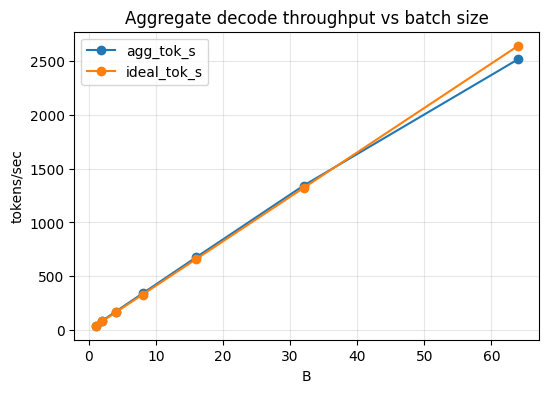

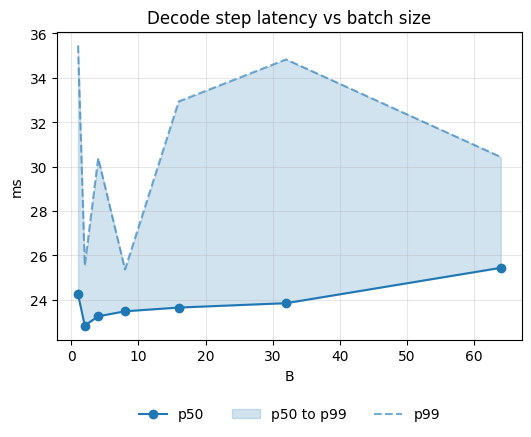

In [20]:
line(scale_df, "B", ["agg_tok_s", "ideal_tok_s"],
     "Aggregate decode throughput vs batch size", "tokens/sec", save="stage3_throughput_vs_batch")

line_band(scale_df, "B", "itl_p50_ms", "itl_p99_ms",
          "Decode step latency vs batch size", "ms", zero=False, save="stage3_itl_vs_batch")

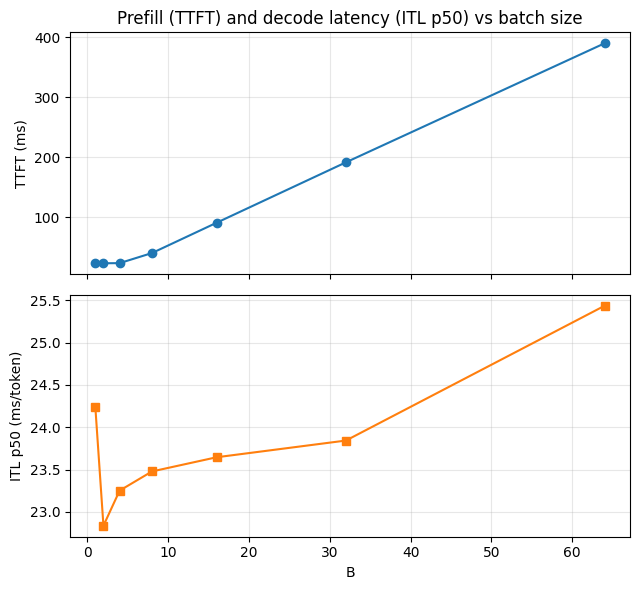

In [21]:
line_stacked(scale_df, "B", "ttft_ms", "itl_p50_ms",
             "Prefill (TTFT) and decode latency (ITL p50) vs batch size",
             "TTFT (ms)", "ITL p50 (ms/token)", save="stage3_ttft_itl_vs_batch", zero=False)

**How to read it.**

- **Throughput.** Aggregate throughput follows the ideal line (the batch-1 rate times `B`) almost exactly across the sweep, and `scaling_eff` stays near 1, dipping only slightly at the largest batch. `B = 64` was the largest batch tested, so the knee where batching stops being free was **not reached**.
- **Step latency.** The p50 decode step is flat as `B` grows, so each step is still limited by launches and weight reads, not by the extra math. The p99 band above it is jitter with no trend in `B`: one slow step among the decode steps of a run is enough to move it, so do not read structure into it.
- **Prefill vs decode.** In the stacked plot TTFT stays flat while the batch holds only a few hundred prompt tokens (up to about `B = 4` here, matching Stage 2's flat region up to about 512 tokens), then grows roughly in proportion to `B` as prefill becomes compute-bound. Decode stays flat. The cost of a bigger batch lands in TTFT, not in the decode step.
- **Per user.** `per_req_tok_s` barely moves, with a small decline at the largest batches: the operator gains almost the whole batch factor, and each user loses little.

---
## 5. A2. The roofline, revisited

**Goal:** place each batch size on the Stage 2 roofline and see why the knee is where it is.

**Concept.** One decode step at batch `B` does `B` times the FLOPs but reads the weights **once**, so its arithmetic intensity grows roughly linearly with `B` (the KV cache is read once per sequence, but it is small next to the weights here). Stage 2 put `B = 1` at about 1 FLOP per byte against a ridge point in the hundreds, so the first doublings of `B` stay deep inside the memory-bound region. The bandwidth ceiling for aggregate throughput is `B / (bytes per step / bandwidth)`, which also grows with `B`. Comparing the measured rate with that ceiling shows how much of the headroom is used.

> **Predict:** does the measured curve follow the bandwidth roof (the slanted line), or does it sit far below it at small `B`?

In [22]:
gpu_name, spec_bw = roofline.spec_bandwidth()
meas_bw = roofline.measure_bandwidth()
w_bytes = roofline.weight_bytes(hf)
ctx = PROMPT_LEN + N_NEW
peak = roofline.compute_peak_tflops(gpu_name)
assert peak is not None, f"add {gpu_name} to FP16_TFLOPS in bench/roofline.py"

itl_by_B = {int(r.B): r.itl_p50_ms / 1000 for r in scale_df.itertuples()}
rpoints = roofline.batch_roofline_points(model, ctx, w_bytes, bpt, meas_bw, itl_by_B)
print(f"{gpu_name}: spec {spec_bw} GB/s, measured copy {meas_bw:.0f} GB/s, ridge {peak * 1000 / meas_bw:.0f} FLOPs/byte")
pd.DataFrame(rpoints).round(3)

Tesla T4: spec 320 GB/s, measured copy 233 GB/s, ridge 279 FLOPs/byte


,B,arithmetic_intensity,achieved_tflops,agg_tok_s,ceiling_agg_tok_s,pct_of_ceiling
0,1,1.014,0.041,41.264,235.723,17.505
1,2,2.023,0.088,87.581,470.325,18.621
2,4,4.028,0.173,172.037,936.201,18.376
3,8,7.980,0.342,340.752,1854.854,18.371
4,16,15.667,0.680,676.668,3641.452,18.582
5,32,30.221,1.348,1342.125,7024.414,19.107
6,64,56.436,2.527,2516.135,13117.664,19.181


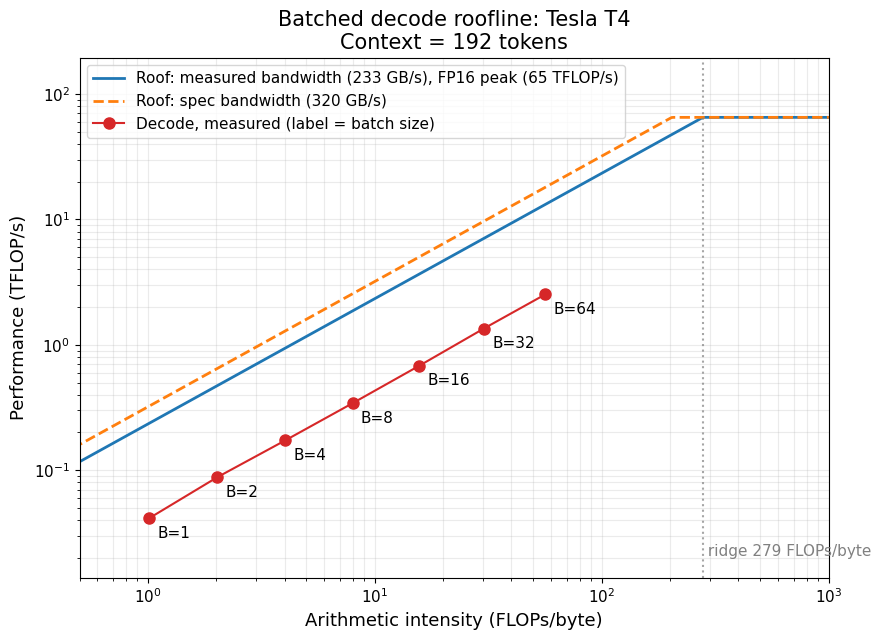

Batched roofline summary
------------------------
GPU:                 Tesla T4
Context length:      192
Measured bandwidth:  233.5 GB/s (spec 320 GB/s)
FP16 compute peak:   65.1 TFLOP/s, ridge 279 FLOPs/byte

   B  FLOPs/byte  TFLOP/s    tok/s   ceiling  % ceiling  AI/ridge
   1        1.01    0.041       41       236      17.5%      0.4%
   2        2.02    0.088       88       470      18.6%      0.7%
   4        4.03    0.173      172       936      18.4%      1.4%
   8        7.98    0.342      341      1855      18.4%      2.9%
  16       15.67    0.680      677      3641      18.6%      5.6%
  32       30.22    1.348     1342      7024      19.1%     10.8%
  64       56.44    2.527     2516     13118      19.2%     20.2%


In [23]:
roofline_batch_plot(rpoints, gpu_name, ctx, spec_bw, meas_bw, peak, save="stage3_roofline_batch")
roofline.print_batch_roofline_summary(rpoints, gpu_name, ctx, spec_bw, meas_bw, peak)

**How to read it.** Each point is one batch size, and moving right means more FLOPs per byte read. All the points sit far left of the ridge, so every batch size is still memory-bound: more work per step is paid for by reading the weights once. `pct_of_ceiling` is the measured aggregate rate divided by the bandwidth ceiling. Here it is a small, nearly constant fraction (rising only slightly), and the same share Stage 2 measured for eager batch-1 decode: the points climb the bandwidth roof **parallel to it**. Batching uses the headroom but does not close the gap to the roof. Had the fraction risen sharply with `B`, batching would also be hiding launch overhead. It did not, so the gap is overhead per step, which `torch.compile` and CUDA graphs attack.

---
## 6. B. Padding waste

**Goal:** measure what different prompt lengths cost inside one batch.

**Concept.** Every prompt in a batch is padded to the longest. If one prompt is 512 tokens and seven are 64, the batch prefills `8 x 512` slots for `512 + 7 x 64` real tokens. Padding slots cost compute only once the prefill is compute-bound (Stage 2: beyond roughly 500 tokens). Below that they hide inside launch overhead, but they **always** cost KV-cache memory.

**Setup.** One batch of `B = 8`, 64 new tokens, prompt lengths spread geometrically from 64 up to 64 times the spread factor. We record two things. One batch is actually run on the GPU (`pad_pct`, `ttft_ms`, `kv_waste_mib`). The padding share is also computed for many random batches (`pad_mean_pct`, with its 5th to 95th percentile range `pad_p5_pct` and `pad_p95_pct`), because padding depends only on which prompt lengths land in the same batch, and a single batch can be lucky or unlucky.

> **Predict:** at spread 8, what share of the prompt slots is padding on average? Will the one batch we run be typical?


In [24]:
B_PAD, PAD_BASE, SPREADS = 8, 64, [1, 2, 4, 8]
N_DRAWS = 1000   # random batches per spread for the padding band; padding depends only on prompt lengths
rows = []
for spread in SPREADS:
    reqs = make_requests(B_PAD, seed=SEED, prompt_lens=spread_prompt_lens(PAD_BASE, spread),
                         short_out=(64, 64), long_out=(64, 64), p_long=0.0)
    run_static(model, reqs, B_PAD, PAD_ID)   # warm-up
    runs = [run_static(model, reqs, B_PAD, PAD_ID) for _ in range(3)]
    w = runs[0].waves[0]
    s = summarize_static(runs[0])
    draws = [padding_pct(spread, k, batch=B_PAD, base=PAD_BASE) for k in range(N_DRAWS)]
    rows.append({
        "spread": spread,
        "longest_prompt": w["T"],
        "real_tokens": w["prompt_real"],
        "pad_pct": 100 * s["pad_frac"],            # the single wave measured here (seed=SEED)
        "pad_mean_pct": np.mean(draws),            # mean over N_DRAWS random batches
        "pad_p5_pct": np.percentile(draws, 5),
        "pad_p95_pct": np.percentile(draws, 95),
        "ttft_ms": 1000 * float(np.median([r.waves[0]["ttft_s"] for r in runs])),
        "kv_waste_mib": (w["prompt_slots"] - w["prompt_real"]) * bpt / 2**20,
    })
pad_df = pd.DataFrame(rows)

pad_mean = pad_df["pad_mean_pct"].to_numpy()
pad_lo = pad_df["pad_p5_pct"].to_numpy()
pad_hi = pad_df["pad_p95_pct"].to_numpy()
pad_df.round(2)

,spread,longest_prompt,real_tokens,pad_pct,pad_mean_pct,pad_p5_pct,pad_p95_pct,ttft_ms,kv_waste_mib
0,1,64,512,0.00,0.00,0.00,0.00,24.03,0.00
1,2,108,727,15.86,24.77,14.69,34.47,35.68,1.61
2,4,181,992,31.49,40.35,25.28,54.10,66.48,5.34
3,8,512,3056,25.39,50.42,33.17,64.78,210.94,12.19


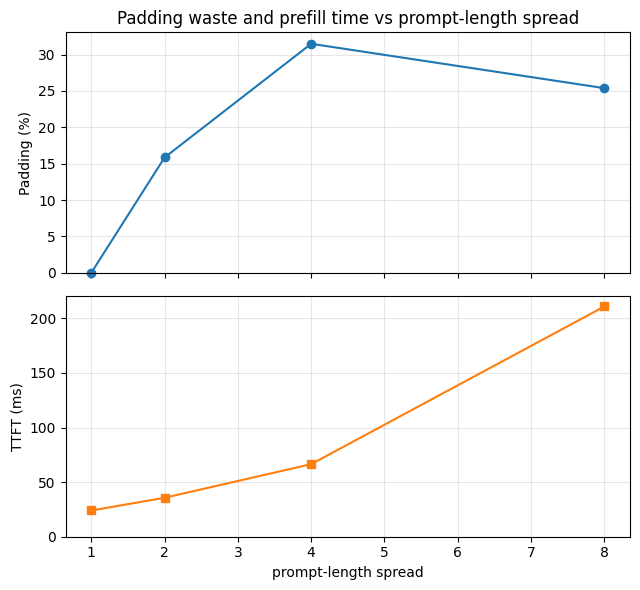

In [25]:
line_stacked(pad_df, "spread", "pad_pct", "ttft_ms", "Padding waste and prefill time vs prompt-length spread",
             "Padding (%)", "TTFT (ms)", save="stage3_padding_and_prefill_vs_spread", xlabel="prompt-length spread")

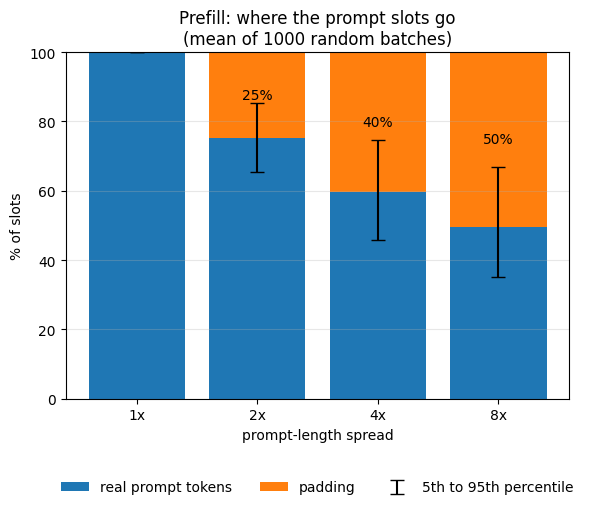

In [26]:
stacked_bar([f"{s}x" for s in pad_df["spread"]],
            {"real prompt tokens": list(100 - pad_mean), "padding": list(pad_mean)},
            f"Prefill: where the prompt slots go\n(mean of {N_DRAWS} random batches)", 
            "% of slots", xlabel="prompt-length spread", annotate=True, ylim=(0, 100),
            marks=(100 - pad_hi, 100 - pad_lo), marks_label="5th to 95th percentile",
            save="stage3_prefill_slots")

**How to read it.**

- **Bars (padding).** Each bar is 100% of the prompt slots of a batch of 8, split into real tokens and padding. They show the *mean over many random batches*, and the black range is the 5th to 95th percentile. Padding grows steadily with the spread, and it is pure waste.
- **The measured batch.** `pad_pct` is one draw. It can land anywhere in that range, or outside it (in the reference run the largest spread fell below it). `ttft_ms` and `kv_waste_mib` come from that same batch, so read them as one example, not an average. The padding and prefill plot shows that measured batch.
- **TTFT.** It is flat for small spreads and climbs steeply once the longest prompt is large (about 512 tokens at the largest spread), the same knee as Stage 2. It rises for two reasons this experiment does not separate: more padded slots, and a longer longest prompt. The cost of padding in *time* shows up only past that knee, while the cost in *memory* (`kv_waste_mib`) is paid from the first padded slot.
- A common mitigation is to batch prompts of similar length together. Try sorting the requests by prompt length before batching and watch the padding drop (exercise 1).

---
## 7. C. Idle decode slots, and the goodput gap

**Goal:** measure what different *output* lengths cost.

**Concept.** A batch decodes until its longest request is done. A request that wanted 32 tokens while a batch-mate wanted 256 sits idle for 224 steps, still occupying a slot and still being computed. Count it by slot-steps: a batch of `B` that runs `S` decode steps has `B x S` slot-steps, and only the steps before each request's own end are useful.

### 7.1 Idle slots vs the share of long requests

32 requests, 128-token prompts, outputs of 32 tokens ("short") or 256 ("long"), static batches of `B = 8`. We vary the share of long requests.

> **Predict:** with 10% long requests and `B = 8`, roughly what fraction of decode slot-steps is idle?

In [27]:
B_WASTE = 8
N_REQ = 16 if QUICK else 32
P_LONG = [0.0, 0.1, 0.25, 0.5]

rows, useful_steps, idle_steps = [], [], []
for p in P_LONG:
    reqs = make_requests(N_REQ, seed=SEED, prompt_lens=(128,), short_out=(32, 32), long_out=(256, 256), p_long=p)
    run = run_static(model, reqs, B_WASTE, PAD_ID)
    s = summarize_static(run, short_max_new=32)
    dec_slots = sum(w["decode_slot_steps"] for w in run.waves)
    dec_useful = sum(w["decode_useful"] for w in run.waves)
    useful_steps.append(dec_useful)
    idle_steps.append(dec_slots - dec_useful)
    rows.append({"p_long": p, "idle_pct": 100 * s["idle_frac"], "goodput_tok_s": s["goodput_tok_s"],
                 "raw_tok_s": s["raw_tok_s"], "makespan_s": s["makespan_s"]})
waste_df = pd.DataFrame(rows)
waste_df.round(2)

,p_long,idle_pct,goodput_tok_s,raw_tok_s,makespan_s
0,0.00,0.00,325.80,325.80,3.14
1,0.10,68.53,106.77,334.24,13.79
2,0.25,63.14,124.73,336.11,24.37
3,0.50,49.41,171.93,338.56,24.20


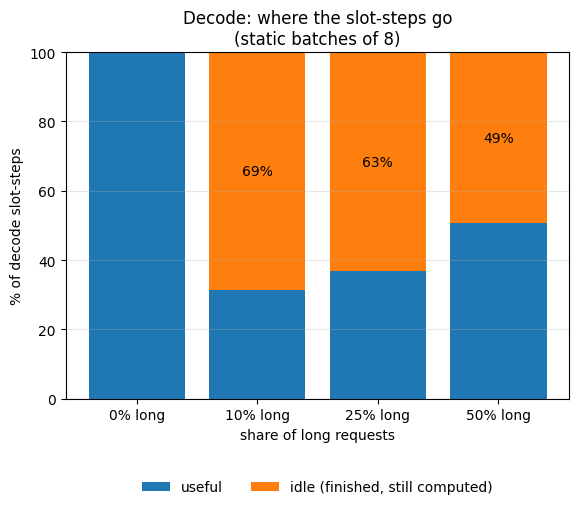

In [28]:
totals = [u + i for u, i in zip(useful_steps, idle_steps)]
stacked_bar([f"{round(100 * p)}% long" for p in P_LONG],
            {"useful": [100 * u / n for u, n in zip(useful_steps, totals)],
             "idle (finished, still computed)": [100 * i / n for i, n in zip(idle_steps, totals)]},
            f"Decode: where the slot-steps go\n(static batches of {B_WASTE})", "% of decode slot-steps",
            xlabel="share of long requests", annotate=True, ylim=(0, 100),
            save="stage3_idle_slots")

**How to read it.** Each bar is 100% of the decode slot-steps for that mix, split into steps that produced a token somebody asked for and steps that did not. `raw_tok_s - goodput_tok_s` is the throughput the GPU spent on slots that were already finished. With 0% long requests every request ends together, so nothing is idle. Idle work is not proportional to the share of long requests: even a few long requests keep a whole batch running.

### 7.2 Does the batching gain survive a realistic mix?

Section 4 used equal lengths. Here the same batch sizes run two workloads, `equal` (128-token prompts, 64 new tokens) and `mixed` (prompts of 32 to 512 tokens, 75% short outputs of 16 to 48 tokens and 25% long outputs of 128 to 256). Each request set is the same for every batch size. Each combination is a single run because the runs are long, so expect some noise.

> **Predict:** at `B = 16`, how much of the `equal` workload's goodput does `mixed` keep?

In [29]:
GOODPUT_BS = [1, 4, 8, 16] if QUICK else [1, 2, 4, 8, 16, 32]
workload_runs = {}   # (workload, B) -> StaticRun
for name in ("equal", "mixed"):
    reqs = make_requests(N_REQ, seed=SEED, **WORKLOADS[name])
    for B in GOODPUT_BS:
        workload_runs[(name, B)] = run_static(model, reqs, B, PAD_ID)
        print(f"{name:5s} B={B:2d}: {workload_runs[(name, B)].total_s:6.1f} s")

rows = []
for (name, B), run in workload_runs.items():
    s = summarize_static(run)
    rows.append({"workload": name, "B": B, "goodput_tok_s": s["goodput_tok_s"], "raw_tok_s": s["raw_tok_s"],
                 "pad_pct": 100 * s["pad_frac"], "idle_pct": 100 * s["idle_frac"], "makespan_s": s["makespan_s"]})
goodput_df = pd.DataFrame(rows)
goodput_df.round(2)

equal B= 1:   49.2 s
equal B= 2:   23.6 s
equal B= 4:   12.0 s
equal B= 8:    6.0 s
equal B=16:    3.1 s
equal B=32:    1.8 s
mixed B= 1:   47.3 s
mixed B= 2:   36.3 s
mixed B= 4:   30.0 s
mixed B= 8:   21.9 s
mixed B=16:   12.7 s
mixed B=32:   10.2 s


,workload,B,goodput_tok_s,raw_tok_s,pad_pct,idle_pct,makespan_s
0,equal,1,41.60,41.60,0.00,0.00,49.23
1,equal,2,86.60,86.60,0.00,0.00,23.65
2,equal,4,170.40,170.40,0.00,0.00,12.02
3,equal,8,338.74,338.74,0.00,0.00,6.05
4,equal,16,653.98,653.98,0.00,0.00,3.13
5,equal,32,1150.72,1150.72,0.00,0.00,1.78
6,mixed,1,41.82,41.82,0.00,0.00,47.34
7,mixed,2,54.57,86.70,27.68,37.44,36.28
8,mixed,4,65.98,171.16,51.79,61.83,30.01
9,mixed,8,90.27,328.98,63.84,72.88,21.93


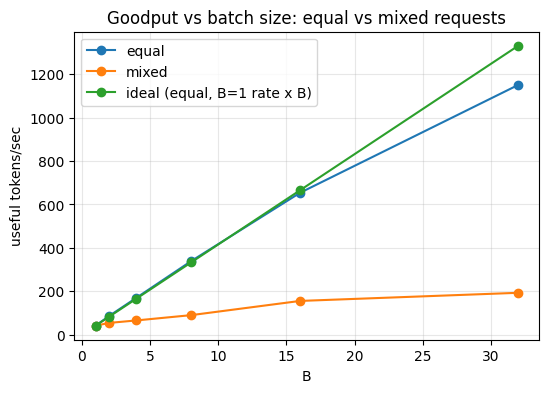

In [30]:
gp = goodput_df.pivot(index="B", columns="workload", values="goodput_tok_s").reset_index()
gp["ideal (equal, B=1 rate x B)"] = gp["B"] * gp.loc[gp["B"] == 1, "equal"].iloc[0]
line(gp, "B", ["equal", "mixed", "ideal (equal, B=1 rate x B)"],
     "Goodput vs batch size: equal vs mixed requests", "useful tokens/sec", save="stage3_goodput_vs_batch")

**How to read it.** The `equal` curve is the best case from section 4, now including prefill and the wave structure: goodput stays close to the ideal line and slips slightly below it at the largest batches. The `mixed` curve is what a real workload looks like. It bends away from `equal` already at small `B` and then flattens, because a larger batch is more likely to contain a long request, so more slots idle for longer (`idle_pct` climbs) and the padded prompt grows (`pad_pct` climbs). Wherever `mixed` bends away from `equal`, batching has stopped paying for itself under static scheduling. That bend is the opening for Stage 4. Each point is a single run, so expect some noise.

### 7.3 Padding and idle slots together

Sections 6 and 7.1 measured the two kinds of waste in separate experiments. On the `mixed` workload we can see both at once as the batch grows. They are both shares of slots, so one 0 to 100 axis is honest, but they are **not the same cost**: idle decode slots turn almost one-for-one into lost goodput, while padding costs prefill time and KV memory.

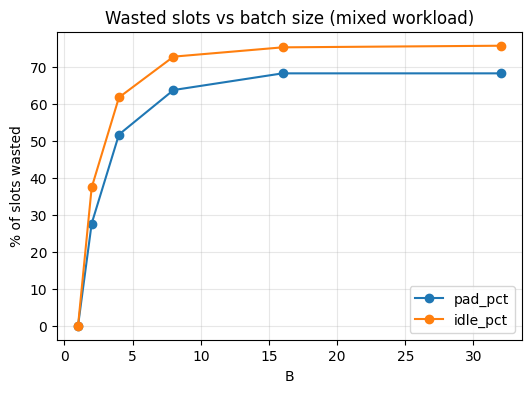

In [31]:
mixed = goodput_df[goodput_df["workload"] == "mixed"]
line(mixed, "B", ["pad_pct", "idle_pct"], "Wasted slots vs batch size (mixed workload)",
     "% of slots wasted", save="stage3_waste_vs_batch")

**How to read it.** Both curves are zero at `B = 1` (nothing to wait for or pad against), rise quickly, then flatten. Padding flattens once every batch already contains the longest prompt, so a bigger batch cannot make it worse, and idle flattens for the same reason on the output side. Idle sits above padding here. Read the heights as "how much of this phase's work is wasted", not as a ranking of which hurts more: they have different denominators and different costs.

---
## 8. D. The latency hit for short requests

**Goal:** show what static batching costs the *users*, not just the GPU.

**Concept.** Static batching returns a batch only when its longest request is done, so a short request is released late. We measure three times per request, all from the start of the run (every request arrives at `t = 0`):

- `finish_s`: when the request's own last token was generated,
- `release_s`: when its batch ended and the response could be returned,
- `blocked = release_s - finish_s`: time spent **finished but waiting**. This is pure static-batching overhead, and it is zero at `B = 1`.

Two effects pull in opposite directions, so we report them separately. Because all requests arrive at once, a larger batch clears the queue sooner, which **shortens** every request's total response time. Blocking **lengthens** it. The total (`short_mean_s`) mixes the two, so `short_blocked_s` is the number that isolates the penalty.

`B = 1` is the sequential baseline. A request is "short" if it asked for 48 tokens or fewer. This section reuses the `mixed` runs from section 7.2, so it takes no extra time.

> **Predict:** at `B = 8`, how long does the average short request sit finished before its batch returns? Is that more or less than the time it took to generate?

In [32]:
SHORT = 48
solo_s = {r.id: workload_runs[("mixed", 1)].waves[r.wave]["wave_s"] for r in workload_runs[("mixed", 1)].results}  # service time alone

rows = []
for B in GOODPUT_BS:
    run = workload_runs[("mixed", B)]
    s = summarize_static(run, short_max_new=SHORT)
    short = [r for r in run.results if r.max_new <= SHORT]
    rows.append({
        "B": B,
        "makespan_s": s["makespan_s"],
        "goodput_tok_s": s["goodput_tok_s"],
        "lat_p50_s": s["lat_p50_s"],
        "lat_p99_s": s["lat_p99_s"],
        "short_mean_s": s["short_mean_s"],
        "short_blocked_s": s["short_blocked_s"],
        "short_slowdown_x": float(np.mean([r.release_s / solo_s[r.id] for r in short])),
        "long_mean_s": s["long_mean_s"],
    })
lat_df = pd.DataFrame(rows)
lat_df.round(2)

,B,makespan_s,goodput_tok_s,lat_p50_s,lat_p99_s,short_mean_s,short_blocked_s,short_slowdown_x,long_mean_s
0,1,47.34,41.82,25.46,47.34,23.84,0.00,35.98,24.70
1,2,36.28,54.57,20.30,36.28,19.09,0.99,28.87,19.45
2,4,30.01,65.98,17.10,30.01,16.80,2.70,25.67,16.40
3,8,21.93,90.27,15.93,21.93,13.01,4.58,19.68,12.29
4,16,12.71,155.79,12.71,12.71,9.61,5.22,14.51,8.85
5,32,10.24,193.27,10.24,10.24,10.24,8.38,15.59,10.24


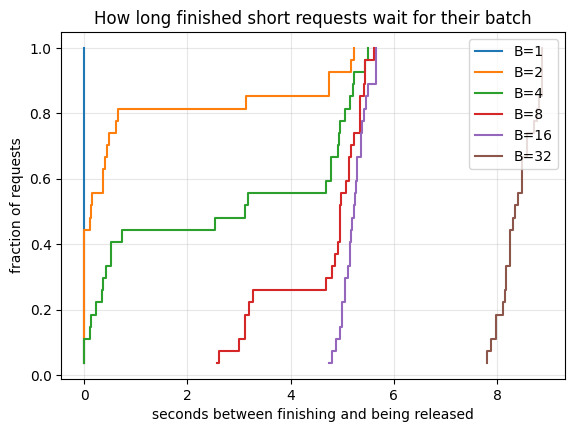

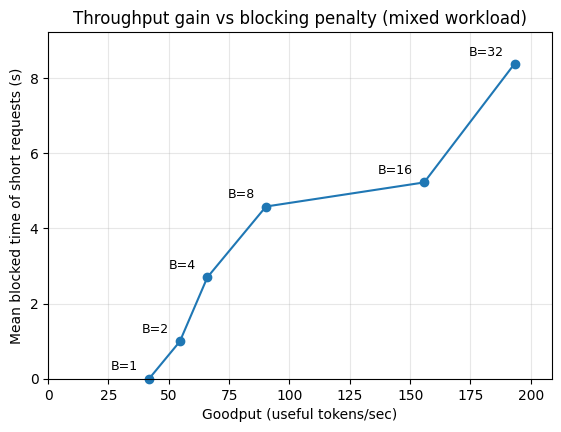

In [33]:
cdf_plot({f"B={B}": [r.release_s - r.finish_s for r in workload_runs[("mixed", B)].results if r.max_new <= SHORT] for B in GOODPUT_BS},
         "How long finished short requests wait for their batch", "seconds between finishing and being released",
         save="stage3_latency_cdf")
tradeoff_curve(lat_df, "goodput_tok_s", "short_blocked_s", "B", "Throughput gain vs blocking penalty (mixed workload)",
               "Goodput (useful tokens/sec)", "Mean blocked time of short requests (s)", save="stage3_tradeoff")

**How to read it.**

- **Blocked time** (`short_blocked_s`, and the CDF) is zero at `B = 1` and grows steadily with `B`: a short request finishes early but cannot leave until the slowest request in its batch is done. The CDF shows the whole distribution, and its curves shift right as `B` grows.
- **Total response time** (`short_mean_s`, `lat_p50_s`, `lat_p99_s`) includes queueing. It falls as `B` grows because the whole workload finishes sooner (`makespan_s`), then flattens or even ticks up at the largest batch, where the whole workload is one batch and nearly all of a short request's response is waiting. Do not read the fall as "batching has no latency cost": it is queueing getting better while blocking gets worse.
- **`short_slowdown_x`** compares a short request's response time with how long it takes alone. Part of it is queueing, part is blocking.
- **`long_mean_s`** can come out *below* **`short_mean_s`**. That is not a bug: with all requests arriving at once, a request's response time depends on which wave it lands in as much as on its own length. Compare blocked time, not the two means.
- With only a few dozen requests, **`lat_p99_s`** is simply the slowest request, which is always the last batch to be released, so it equals the makespan at every batch size. It is shown for completeness, not as a separate tail measurement.
- The tradeoff curve is the picture to remember: **as goodput rises with `B`, so does the time finished requests spend waiting for strangers.** The curve is cheap for a while and steepest at the end: past a mid-sized batch, extra goodput costs much more blocking. Continuous batching (Stage 4) keeps the throughput and removes the blocking.

---
## 9. E. KV memory over-allocation

**Goal:** count how much of the KV cache a static batch actually uses.

**Concept.** Each batch allocates one rectangle of `B x (longest prompt + longest output)` token slots per layer, whatever the individual requests need. The unused slots are padding, finished requests' tail, and room that was never needed. Serving systems usually reserve even more, because the true output length is unknown: they reserve the model's maximum context for every sequence. This section reuses the `mixed` runs from section 7.2, so it takes no extra time.

### 9.1 Measured utilization

`kv_util` is the KV bytes actually holding tokens divided by the bytes allocated for the batch. `kv_util_if_2048` shows what it would be if every slot reserved 2048 tokens up front, as a server that does not know the output length would.

In [34]:
MAX_CTX = 2048
rows = []
for B in GOODPUT_BS:
    run = workload_runs[("mixed", B)]
    s = summarize_static(run)
    used = sum(w["kv_used_bytes"] for w in run.waves)
    rows.append({
        "B": B,
        "kv_alloc_mib_per_batch": max(w["kv_alloc_bytes"] for w in run.waves) / 2**20,
        "kv_util_pct": 100 * s["kv_util"],
        "kv_util_if_2048_pct": 100 * used / sum(w["B"] * MAX_CTX * bpt for w in run.waves),
    })
kv_df = pd.DataFrame(rows)
kv_df.round(2)

,B,kv_alloc_mib_per_batch,kv_util_pct,kv_util_if_2048_pct
0,1,6.55,100.00,10.88
1,2,13.10,69.36,10.88
2,4,35.39,44.98,10.88
3,8,71.06,33.14,10.88
4,16,143.25,29.34,10.88
5,32,286.50,29.17,10.88


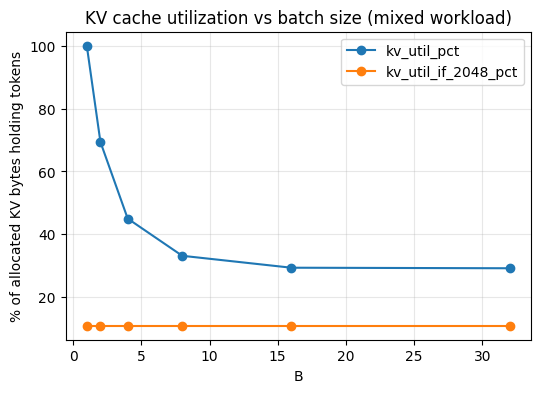

In [35]:
line(kv_df, "B", ["kv_util_pct", "kv_util_if_2048_pct"], "KV cache utilization vs batch size (mixed workload)",
     "% of allocated KV bytes holding tokens", save="stage3_kv_util")

**How to read it.** Utilization starts at 100% at `B = 1` (one request fills its own rectangle), falls as the batch grows, then levels off: the longest prompt and the longest output in each batch set the rectangle, and the more requests share it the more of it is padding and finished tail. Reserving the model's maximum context for every sequence (second line) keeps utilization low at every batch size, because the reservation does not depend on what a request needs.

### 9.2 Why it matters: how many sequences fit

Qwen2.5-0.5B is tiny: its KV cache costs 12 KiB per token, so memory never limits the batch on a 15 GiB GPU. Bigger models differ by orders of magnitude. The table below is an **analytic projection, not a measurement**: for an 8 GiB KV budget, how many sequences fit if each reserves 2048 tokens (contiguous preallocation) vs if each only held the tokens it actually used (the mean length of our `mixed` requests)?

In [36]:
KV_BUDGET_GIB = 8
mean_ctx = float(np.mean([len(r.prompt_ids) + r.max_new for r in make_requests(N_REQ, seed=SEED, **WORKLOADS["mixed"])]))
rows = []
for name, geo in roofline.KV_GEOMETRY.items():
    cap = roofline.kv_capacity(geo, KV_BUDGET_GIB, MAX_CTX, mean_ctx)
    rows.append({"model": name, **cap, "gain_x": cap["seqs_actual"] / max(cap["seqs_reserved"], 1)})
proj_df = pd.DataFrame(rows)
print(f"mean tokens per request in the mixed workload: {mean_ctx:.0f}; budget {KV_BUDGET_GIB} GiB; reserve {MAX_CTX} per sequence")
proj_df.round(1)

mean tokens per request in the mixed workload: 224; budget 8 GiB; reserve 2048 per sequence


,model,kib_per_token,seqs_reserved,seqs_actual,gain_x
0,Qwen2.5-0.5B,12.0,341,3122,9.2
1,Qwen2.5-7B,56.0,73,669,9.2
2,Llama-2-7B (MHA),512.0,8,73,9.1


**How to read it.** For the small model both columns are large and memory does not bind. For a model with a big KV footprint per token (the multi-head-attention Llama-style row), contiguous reservation limits the batch to a handful of sequences while the actual tokens would fit many more. Stage 5 (paged KV cache) closes that gap by allocating small blocks on demand, and that is what lets Stage 4's scheduler keep the batch full. The ratio between the two columns is about the same for every model, because it depends only on the reserved context versus the actual mean length. What the model changes is whether the absolute count is large enough to matter.

---
## 10. Save results

`results/stage3.json` holds everything needed to re-plot without re-running:

- `env` and `config`: GPU, library versions, model revision, and every experiment parameter,
- `batch_scaling`: section 4 (TTFT, ITL, aggregate and per-request tok/s, scaling efficiency, KV MiB),
- `roofline`: bandwidths, ridge point and one point per batch size (section 5),
- `padding`: section 6 (the measured batch, plus the mean and percentile range over many random batches), `waste` (idle slots and goodput vs batch size, section 7), `latency` (section 8),
- `kv_memory`: measured utilization and the analytic projection (section 9).

Final published numbers should come from one consistent environment.

In [37]:
out = {
    "env": {**ENV, "max_pos": MAX_POS},
    "config": {
        "seed": SEED, "quick": QUICK, "n_requests": N_REQ,
        "scaling": {"prompt_len": PROMPT_LEN, "n_new": N_NEW, "batch_sizes": BATCH_SIZES},
        "padding": {"batch_size": B_PAD, "base_prompt_len": PAD_BASE, "spreads": SPREADS, "n_new": 64, "n_draws": N_DRAWS},
        "waste": {"batch_size": B_WASTE, "p_long": P_LONG, "short_new": 32, "long_new": 256, "prompt_len": 128},
        "workloads": WORKLOADS, "goodput_batch_sizes": GOODPUT_BS, "short_max_new": SHORT,
    },
    "batch_scaling": scale_df.round(4).to_dict(orient="records"),
    "roofline": {
        "context_len": ctx, "spec_bw_gbps": spec_bw, "measured_bw_gbps": meas_bw, "weight_bytes": w_bytes,
        "kv_bytes_per_token": bpt, "compute_peak_tflops": peak, "ridge_measured": peak * 1000 / meas_bw,
        "points": [{k: round(v, 4) for k, v in p.items()} for p in rpoints],
    },
    "padding": pad_df.round(4).to_dict(orient="records"),
    "waste": {
        "idle_vs_long_fraction": waste_df.round(4).to_dict(orient="records"),
        "goodput_vs_batch": goodput_df.round(4).to_dict(orient="records"),
    },
    "latency": lat_df.round(4).to_dict(orient="records"),
    "kv_memory": {
        "measured": kv_df.round(4).to_dict(orient="records"),
        "projection": proj_df.round(4).to_dict(orient="records"),
        "assumptions": {"budget_gib": KV_BUDGET_GIB, "reserved_ctx": MAX_CTX, "mean_ctx": mean_ctx},
    },
}
save_results("results/stage3.json", out)

saved results/stage3.json


### Figure inventory

Every figure was written to `results/` by the cell that produced it. This cell lists them and fails if one is missing.

In [38]:
FIGURES = {
    "stage3_throughput_vs_batch.png": "Aggregate decode tok/s vs batch size, with the ideal line (section 4)",
    "stage3_itl_vs_batch.png": "Decode step latency p50 and p99 vs batch size (section 4)",
    "stage3_ttft_itl_vs_batch.png": "Prefill (TTFT) and decode (ITL p50) time vs batch size, stacked panels (section 4)",
    "stage3_roofline_batch.png": "Batched decode on the roofline, one point per batch size (section 5)",
    "stage3_padding_and_prefill_vs_spread.png": "Padding share and prefill time of the measured batch vs prompt-length spread (section 6.B)",
    "stage3_prefill_slots.png": "Prefill: where the prompt slots go (mean of random batches), by share of prompt-length spread (section 6.B)",
    "stage3_idle_slots.png": "Decode: where the slot-steps go (static batches of 8), by share of long requests (section 7.1)",
    "stage3_goodput_vs_batch.png": "Goodput vs batch size, equal vs mixed requests (section 7.2)",
    "stage3_waste_vs_batch.png": "Padding and idle shares of slots vs batch size, mixed workload (section 7.3)",
    "stage3_latency_cdf.png": "CDF of how long finished short requests wait for their batch, by batch size (section 8)",
    "stage3_tradeoff.png": "Goodput vs blocking time of short requests, one point per batch size, mixed workload (section 8)",
    "stage3_kv_util.png": "KV cache utilization vs batch size, mixed workload (section 9)",
}
missing = [f for f in FIGURES if not os.path.exists(f"results/{f}")]
assert not missing, f"missing figures: {missing}"
pd.DataFrame({"file": list(FIGURES), "what it shows": list(FIGURES.values())})

,file,what it shows
0,stage3_throughput_vs_batch.png,"Aggregate decode tok/s vs batch size, with the..."
1,stage3_itl_vs_batch.png,Decode step latency p50 and p99 vs batch size ...
2,stage3_ttft_itl_vs_batch.png,Prefill (TTFT) and decode (ITL p50) time vs ba...
3,stage3_roofline_batch.png,"Batched decode on the roofline, one point per ..."
4,stage3_padding_and_prefill_vs_spread.png,Padding share and prefill time of the measured...
5,stage3_prefill_slots.png,Prefill: where the prompt slots go (mean of ra...
6,stage3_idle_slots.png,Decode: where the slot-steps go (static batche...
7,stage3_goodput_vs_batch.png,"Goodput vs batch size, equal vs mixed requests..."
8,stage3_waste_vs_batch.png,Padding and idle shares of slots vs batch size...
9,stage3_latency_cdf.png,CDF of how long finished short requests wait f...


---
## 11. Publish results (and code, if this is the newest notebook) to GitHub (optional)

Set `PUSH = True` to push this run to your repo. The cell below is identical in every notebook of the series except `PUSH` and `COMMIT_MSG`. It calls `publish()` from `bench/publish.py`, which clones the repo, pulls, copies `results/` in, and copies `minivllm/` and `bench/` in only if this notebook's stage is at least the stage recorded in the repo (`minivllm/STAGE`). It then commits and pushes, printing git's output and raising an error if any git step fails. This is the newest notebook, so it publishes code as well as results. An older notebook rerun later pushes results only and cannot overwrite this code.

It needs a Kaggle secret named `minivllm-github-token` holding a GitHub token with write access. The repo name and git identity are constants at the top of `bench/publish.py`. The token is used only for the clone, pull and push commands and is not stored in the repo's git config.

In [39]:
PUSH = True                               # True: publish to GitHub at the end of the run
COMMIT_MSG = "Stage 3: static batching"   # the only other line that differs between notebooks
FORCE_CODE = False                        # leave False: code is published automatically from the newest stage

if PUSH:
    from kaggle_secrets import UserSecretsClient
    from bench.publish import publish, SECRET_NAME
    publish(token=UserSecretsClient().get_secret(SECRET_NAME), message=COMMIT_MSG, force_code=FORCE_CODE)

Cloning into 'mini-vllm'...
remote: Enumerating objects: 488, done.        
remote: Counting objects: 100% (200/200), done.        
remote: Compressing objects: 100% (159/159), done.        
remote: Total 488 (delta 79), reused 135 (delta 37), pack-reused 288 (from 1)        
Receiving objects: 100% (488/488), 10.29 MiB | 27.16 MiB/s, done.
Resolving deltas: 100% (207/207), done.
Already up to date.
From https://github.com/chizkidd/minivllm
 * branch            HEAD       -> FETCH_HEAD
notebook stage 3, repo code stage 3: publishing code and results
[main 221ca73] Stage 3: static batching
 14 files changed, 217 insertions(+), 211 deletions(-)
Enumerating objects: 35, done.
Counting objects: 100% (35/35), done.
Delta compression using up to 4 threads
Compressing objects: 100% (19/19), done.
Writing objects: 100% (19/19), 529.22 KiB | 17.07 MiB/s, done.
Total 19 (delta 10), reused 0 (delta 0), pack-reused 0
To https://github.com/chizkidd/minivllm.git
   41a6afa..221ca73  HEAD -> main


---
## 12. Summary

In [40]:
# b1 = scale_df.loc[scale_df["B"] == 1].iloc[0]
# top = scale_df.loc[scale_df["B"].idxmax()]
# rp = pd.DataFrame(rpoints)
# last = GOODPUT_BS[-1]
# eq, mx = (goodput_df[(goodput_df.workload == w) & (goodput_df.B == last)].iloc[0] for w in ("equal", "mixed"))
# lb = lat_df[lat_df.B == last].iloc[0]
# mixed_waste = waste_df[waste_df["p_long"] > 0]

# print(f"Gain: aggregate {b1['agg_tok_s']:.0f} tok/s at B=1 -> {top['agg_tok_s']:.0f} tok/s at B={int(top['B'])} "
#       f"({top['agg_tok_s'] / b1['agg_tok_s']:.1f}x for {int(top['B'])}x the batch)")
# print(f"Step latency: ITL p50 stays within {scale_df['itl_p50_ms'].min():.1f} to {scale_df['itl_p50_ms'].max():.1f} ms from B=1 to B={int(top['B'])} "
#       f"(the largest batch tested, so the knee was not reached); each request still gets {scale_df['per_req_tok_s'].min():.0f} to {scale_df['per_req_tok_s'].max():.0f} tok/s")
# print(f"Roofline: arithmetic intensity {rp['arithmetic_intensity'].iloc[0]:.1f} -> {rp['arithmetic_intensity'].iloc[-1]:.0f} FLOPs/byte, "
#       f"yet the measured rate stays at {rp['pct_of_ceiling'].min():.0f} to {rp['pct_of_ceiling'].max():.0f}% of the bandwidth ceiling (overhead, not bandwidth)")
# print(f"Prefill cost: TTFT {scale_df['ttft_ms'].iloc[0]:.0f} ms at B=1 -> {top['ttft_ms']:.0f} ms at B={int(top['B'])}")
# print("Mean padding share of prompt slots by spread factor: "
#         + ", ".join(f"{int(s)}x: {p:.0f}%" for s, p in zip(pad_df["spread"], pad_df["pad_mean_pct"]))
#         + f" (up to {pad_df['kv_waste_mib'].max():.0f} MiB of KV held by padding in the measured batch)")
# print(f"Idle slots (B={B_WASTE}): {mixed_waste['idle_pct'].min():.0f}% to {mixed_waste['idle_pct'].max():.0f}% of decode slot-steps with any long requests; "
#       f"goodput {waste_df['goodput_tok_s'].iloc[0]:.0f} tok/s with none long vs {waste_df['goodput_tok_s'].min():.0f} tok/s at its worst, while raw stays near {waste_df['raw_tok_s'].mean():.0f} tok/s")
# print(f"At B={last}: equal goodput {eq['goodput_tok_s']:.0f} tok/s vs mixed {mx['goodput_tok_s']:.0f} tok/s "
#       f"({100 * mx['goodput_tok_s'] / eq['goodput_tok_s']:.0f}% kept), idle {mx['idle_pct']:.0f}%")
# print(f"Short requests at B={last} sit finished-but-blocked {lb['short_blocked_s']:.1f} s of their {lb['short_mean_s']:.1f} s response "
#       f"({100 * lb['short_blocked_s'] / lb['short_mean_s']:.0f}%)")
# print(f"KV utilization at B={last}: {kv_df['kv_util_pct'].iloc[-1]:.0f}% of the batch rectangle, "
#       f"{kv_df['kv_util_if_2048_pct'].iloc[-1]:.1f}% if each slot reserved {MAX_CTX} tokens")

In [41]:
from IPython.display import Markdown, display

lines = []
say = lines.append

b1 = scale_df.loc[scale_df["B"] == 1].iloc[0]
top = scale_df.loc[scale_df["B"].idxmax()]
rp = pd.DataFrame(rpoints)
last = GOODPUT_BS[-1]
eq, mx = (goodput_df[(goodput_df.workload == w) & (goodput_df.B == last)].iloc[0] for w in ("equal", "mixed"))
lb = lat_df[lat_df.B == last].iloc[0]
mixed_waste = waste_df[waste_df["p_long"] > 0]

say(f"**Gain:** aggregate {b1['agg_tok_s']:.0f} tok/s at B=1 -> {top['agg_tok_s']:.0f} tok/s at B={int(top['B'])} "
    f"({top['agg_tok_s'] / b1['agg_tok_s']:.1f}x for {int(top['B'])}x the batch)")
say(f"**Step latency:** ITL p50 stays within {scale_df['itl_p50_ms'].min():.1f} to {scale_df['itl_p50_ms'].max():.1f} ms from B=1 to B={int(top['B'])} "
    f"(the largest batch tested, so the knee was not reached); each request still gets {scale_df['per_req_tok_s'].min():.0f} to {scale_df['per_req_tok_s'].max():.0f} tok/s")
say(f"**Roofline:** arithmetic intensity {rp['arithmetic_intensity'].iloc[0]:.1f} -> {rp['arithmetic_intensity'].iloc[-1]:.0f} FLOPs/byte, "
    f"yet the measured rate stays at {rp['pct_of_ceiling'].min():.0f} to {rp['pct_of_ceiling'].max():.0f}% of the bandwidth ceiling (overhead, not bandwidth)")
say(f"**Prefill cost:** TTFT {scale_df['ttft_ms'].iloc[0]:.0f} ms at B=1 -> {top['ttft_ms']:.0f} ms at B={int(top['B'])}")
say("**Mean padding share of prompt slots by spread factor:** "
    + ", ".join(f"{int(s)}x: {p:.0f}%" for s, p in zip(pad_df["spread"], pad_df["pad_mean_pct"]))
    + f" (up to {pad_df['kv_waste_mib'].max():.0f} MiB of KV held by padding in the measured batch)")
say(f"**Idle slots (B={B_WASTE}):** {mixed_waste['idle_pct'].min():.0f}% to {mixed_waste['idle_pct'].max():.0f}% of decode slot-steps with any long requests; "
    f"goodput {waste_df['goodput_tok_s'].iloc[0]:.0f} tok/s with none long vs {waste_df['goodput_tok_s'].min():.0f} tok/s at its worst, while raw stays near {waste_df['raw_tok_s'].mean():.0f} tok/s")
say(f"**At B={last}:** equal goodput {eq['goodput_tok_s']:.0f} tok/s vs mixed {mx['goodput_tok_s']:.0f} tok/s "
    f"({100 * mx['goodput_tok_s'] / eq['goodput_tok_s']:.0f}% kept), idle {mx['idle_pct']:.0f}%")
say(f"**Short requests at B={last}** sit finished-but-blocked {lb['short_blocked_s']:.1f} s of their {lb['short_mean_s']:.1f} s response "
    f"({100 * lb['short_blocked_s'] / lb['short_mean_s']:.0f}%)")
say(f"**KV utilization** at B={last}: {kv_df['kv_util_pct'].iloc[-1]:.0f}% of the batch rectangle, "
    f"{kv_df['kv_util_if_2048_pct'].iloc[-1]:.1f}% if each slot reserved {MAX_CTX} tokens")

display(Markdown("\n".join(f"- {l}" for l in lines)))

- **Gain:** aggregate 41 tok/s at B=1 -> 2516 tok/s at B=64 (61.0x for 64x the batch)
- **Step latency:** ITL p50 stays within 22.8 to 25.4 ms from B=1 to B=64 (the largest batch tested, so the knee was not reached); each request still gets 39 to 44 tok/s
- **Roofline:** arithmetic intensity 1.0 -> 56 FLOPs/byte, yet the measured rate stays at 18 to 19% of the bandwidth ceiling (overhead, not bandwidth)
- **Prefill cost:** TTFT 24 ms at B=1 -> 390 ms at B=64
- **Mean padding share of prompt slots by spread factor:** 1x: 0%, 2x: 25%, 4x: 40%, 8x: 50% (up to 12 MiB of KV held by padding in the measured batch)
- **Idle slots (B=8):** 49% to 69% of decode slot-steps with any long requests; goodput 326 tok/s with none long vs 107 tok/s at its worst, while raw stays near 334 tok/s
- **At B=32:** equal goodput 1151 tok/s vs mixed 193 tok/s (17% kept), idle 76%
- **Short requests at B=32** sit finished-but-blocked 8.4 s of their 10.2 s response (82%)
- **KV utilization** at B=32: 29% of the batch rectangle, 10.9% if each slot reserved 2048 tokens

In [42]:
from IPython.display import Markdown, display

def show_table(rows, headers=("Metric", "Result", "Note")):
    esc = lambda c: str(c).replace("|", "\\|")   # a literal | would break the table
    out = ["| " + " | ".join(headers) + " |", "|" + "|".join(["---"] * len(headers)) + "|"]
    for r in rows:
        out.append("| " + " | ".join([f"**{esc(r[0])}**"] + [esc(c) for c in r[1:]]) + " |")
    display(Markdown("\n".join(out)))

show_table([
    ("Gain",
     f"{b1['agg_tok_s']:.0f} -> {top['agg_tok_s']:.0f} tok/s aggregate (B=1 -> B={int(top['B'])})",
     f"{top['agg_tok_s'] / b1['agg_tok_s']:.1f}x for {int(top['B'])}x the batch"),

    ("Step latency",
     f"ITL p50 within {scale_df['itl_p50_ms'].min():.1f} to {scale_df['itl_p50_ms'].max():.1f} ms",
     f"B={int(top['B'])} is the largest batch tested, so the knee was not reached; "
     f"each request still gets {scale_df['per_req_tok_s'].min():.0f} to {scale_df['per_req_tok_s'].max():.0f} tok/s"),

    ("Roofline",
     f"intensity: {rp['arithmetic_intensity'].iloc[0]:.1f} -> {rp['arithmetic_intensity'].iloc[-1]:.0f} FLOPs/byte; "
     f"{rp['pct_of_ceiling'].min():.0f} to {rp['pct_of_ceiling'].max():.0f}% of bandwidth ceiling",
     "overhead, not bandwidth"),

    ("Prefill cost",
     f"TTFT {scale_df['ttft_ms'].iloc[0]:.0f} -> {top['ttft_ms']:.0f} ms",
     f"B=1 -> B={int(top['B'])}"),

    ("Mean padding share by spread factor",
     ", ".join(f"{int(s)}x: {p:.0f}%" for s, p in zip(pad_df["spread"], pad_df["pad_mean_pct"])),
     f"up to {pad_df['kv_waste_mib'].max():.0f} MiB of KV held by padding in the measured batch"),

    (f"Idle slots (B={B_WASTE})",
     f"{mixed_waste['idle_pct'].min():.0f}% to {mixed_waste['idle_pct'].max():.0f}% of decode slot-steps",
     f"with any long requests; goodput {waste_df['goodput_tok_s'].iloc[0]:.0f} tok/s with none long vs "
     f"{waste_df['goodput_tok_s'].min():.0f} at worst, raw stays near {waste_df['raw_tok_s'].mean():.0f}"),

    (f"Equal vs mixed (B={last})",
     f"goodput {eq['goodput_tok_s']:.0f} vs {mx['goodput_tok_s']:.0f} tok/s",
     f"{100 * mx['goodput_tok_s'] / eq['goodput_tok_s']:.0f}% kept, idle {mx['idle_pct']:.0f}%"),

    (f"Short requests (B={last})",
     f"blocked {lb['short_blocked_s']:.1f} s of a {lb['short_mean_s']:.1f} s response",
     f"{100 * lb['short_blocked_s'] / lb['short_mean_s']:.0f}% of their latency is waiting"),

    (f"KV utilization (B={last})",
     f"{kv_df['kv_util_pct'].iloc[-1]:.0f}% of the batch rectangle",
     f"{kv_df['kv_util_if_2048_pct'].iloc[-1]:.1f}% if each slot reserved {MAX_CTX} tokens"),
])

| Metric | Result | Note |
|---|---|---|
| **Gain** | 41 -> 2516 tok/s aggregate (B=1 -> B=64) | 61.0x for 64x the batch |
| **Step latency** | ITL p50 within 22.8 to 25.4 ms | B=64 is the largest batch tested, so the knee was not reached; each request still gets 39 to 44 tok/s |
| **Roofline** | intensity: 1.0 -> 56 FLOPs/byte; 18 to 19% of bandwidth ceiling | overhead, not bandwidth |
| **Prefill cost** | TTFT 24 -> 390 ms | B=1 -> B=64 |
| **Mean padding share by spread factor** | 1x: 0%, 2x: 25%, 4x: 40%, 8x: 50% | up to 12 MiB of KV held by padding in the measured batch |
| **Idle slots (B=8)** | 49% to 69% of decode slot-steps | with any long requests; goodput 326 tok/s with none long vs 107 at worst, raw stays near 334 |
| **Equal vs mixed (B=32)** | goodput 1151 vs 193 tok/s | 17% kept, idle 76% |
| **Short requests (B=32)** | blocked 8.4 s of a 10.2 s response | 82% of their latency is waiting |
| **KV utilization (B=32)** | 29% of the batch rectangle | 10.9% if each slot reserved 2048 tokens |

### What we learned

#### Questions

- **Is batching nearly free?** (Section 4 and 5: up to which batch size did ITL stay flat, and did the points follow the bandwidth roof?)
- **What does one more sequence cost?** (Per-request tok/s falls even as aggregate tok/s rises: who benefits, the operator or the user?)
- **Where does static batching waste work?** (Padding in the prompt, idle slots after short requests finish, and KV memory for both.)
- **Who pays?** (Short requests wait for the longest request in their batch.)


#### Answers

- **Batching is nearly free here.** Aggregate throughput scales almost linearly with the batch while the decode step stays flat, so each request keeps almost the same speed whether it is served alone or with many others. The largest batch tested was `B = 64`, so the knee where the step stops being free was not reached.
- **The cost moved to TTFT.** It stays flat while the batch holds up to about 512 prompt tokens, as in Part 1, then grows roughly in proportion to the batch as prefill becomes compute-bound.
- **Batching does not close the overhead gap.** Arithmetic intensity grows in proportion to `B`, yet the measured rate stays at a small, nearly constant fraction of the bandwidth ceiling, the same share as Part 1's eager batch-1 decode. The points climb the roof parallel to it. The rest is launch overhead, which `torch.compile` and CUDA graphs attack.
- **Static batching wastes work in three ways.**
  - **Padding:** averaged over many random batches it grows steadily with the prompt-length spread (roughly half the prompt slots at the largest spread tested), though a single batch can land well above or below the average. Padded slots always cost KV memory.
  - **Idle decode slots:** with any long requests most decode slot-steps are idle. Raw throughput stays flat while goodput collapses.
  - **KV memory:** only a minority of the allocated bytes hold tokens once batches are large, and far fewer if every slot reserved the maximum context.
- **The gain does not survive a realistic mix.** With equal lengths goodput keeps scaling with the batch. With mixed lengths it rises far more slowly and flattens, with most slot-steps idle at large batches.
- **Short requests pay.** Total response time falls as `B` grows because the queue clears sooner, but blocked time (finished, waiting for the batch) rises steadily and at the largest batch is most of a short request's response.
- **Bug to remember:** a padding row with no real key to attend to makes the softmax NaN, and `0 x NaN` poisons the real tokens. Letting every row attend to itself fixes it.
### Next: Stage 4, continuous batching

Static batching makes everything wait for the slowest request. **Continuous batching** removes that by scheduling at the level of one decode step: when a request finishes, its slot is freed immediately and a waiting request is prefilled into it, so the batch stays full and nobody waits for a stranger's long answer. That needs a scheduler with waiting and running queues, per-sequence cache lengths (so the cache is no longer one rectangle) and a load generator to measure throughput against p99 latency. It also makes the KV waste measured here the next bottleneck, which is what Stage 5 (paged KV cache) fixes.

### Exercises

1. **Bucket by length.** Sort the `mixed` requests by prompt length before batching. How much does `pad_pct` drop, and what does it do to latency for the long prompts?
2. **Sort by expected output length.** If a server could predict output length, how much of the idle-slot waste would grouping similar lengths remove?
3. **GQA copy.** `repeat_interleave` copies the KV heads every step, and that copy grows with `B`. Replace it with `enable_gqa=True` in `F.scaled_dot_product_attention` and re-run section 4.
4. **Chunk the prompts.** What happens to TTFT at `B = 8` and spread 8 if we prefill the long prompt in chunks of 128 tokens?

### Hints for exercises

1. **Bucket by length.** Sort the `mixed` requests by prompt length before batching. How much does the padding share drop, and what happens to the idle decode slots and to the latency of the long prompts? *Hint (CPU only, padding depends only on prompt lengths):*

   ```python
   reqs = make_requests(N_REQ, seed=SEED, **WORKLOADS["mixed"])
   def pad_share(reqs, B):
       waves = [reqs[i:i + B] for i in range(0, len(reqs), B)]
       real = sum(len(r.prompt_ids) for r in reqs)
       slots = sum(len(w) * max(len(r.prompt_ids) for r in w) for w in waves)
       return 100 * (1 - real / slots)
   
   for B in (4, 8, 16):
       print(B, pad_share(reqs, B), pad_share(sorted(reqs, key=lambda r: len(r.prompt_ids)), B))
   ```

>_**Predict first: should the idle decode slots drop too?**_


### References

- Yu et al., *Orca: A Distributed Serving System for Transformer-Based Generative Models* (OSDI 2022), the origin of iteration-level (continuous) scheduling: https://www.usenix.org/conference/osdi22/presentation/yu
- Kwon et al., *Efficient Memory Management for LLM Serving with PagedAttention* (vLLM): https://arxiv.org/abs/2309.06180
- Williams, Waterman, Patterson, *Roofline: An Insightful Visual Performance Model*: https://dl.acm.org/doi/10.1145/1498765.1498785

---

# Appendix

Refer to the simple examples below to understand how `left_pad`, `Layout`, `KVCache`, and `make_requests` work.

## A.1. KV Caching (`KVCache`)

In [43]:
import torch
from minivllm.kv_cache import KVCache

n_layers, batch, n_kv_heads, max_len, head_dim = 24, 2, 2, 13, 64
c = KVCache(n_layers, batch, n_kv_heads, max_len, head_dim, device="cpu", dtype=torch.float16)

bpt = KVCache.bytes_per_token(n_layers, n_kv_heads, head_dim, c.k.element_size())
print("shape:", tuple(c.k.shape))
print("nbytes:", c.nbytes, " via bytes_per_token:", bpt * batch * max_len)
assert c.nbytes == bpt * batch * max_len

# prefill: T = 5, all 24 layers write the same columns
k = torch.randn(2, 2, 5, 64, dtype=torch.float16)
for layer in range(24):
    ck, cv = c.update(layer, k, k)
print("after prefill writes, length:", c.length, "(not advanced yet)")
print("returned shape:", tuple(ck.shape))
c.advance(5)

# decode: T = 1
k1 = torch.randn(2, 2, 1, 64, dtype=torch.float16)
for layer in range(24):
    ck, cv = c.update(layer, k1, k1)
print("decode returned shape:", tuple(ck.shape), " length before advance:", c.length)
c.advance(1)
print("length now:", c.length)

# the returned tensor is a view, and not contiguous
print("shares storage with cache:", ck.data_ptr() == c.k[23].data_ptr())
print("contiguous:", ck.is_contiguous())

# overflow guard
try:
    c.update(0, torch.randn(2, 2, 20, 64, dtype=torch.float16), torch.randn(2, 2, 20, 64, dtype=torch.float16))
except AssertionError as e:
    print("caught:", e)

shape: (24, 2, 2, 13, 64)
nbytes: 319488  via bytes_per_token: 319488
after prefill writes, length: 0 (not advanced yet)
returned shape: (2, 2, 5, 64)
decode returned shape: (2, 2, 6, 64)  length before advance: 5
length now: 6
shares storage with cache: True
contiguous: False
caught: KV cache overflow


## A.2. Batching (`left_pad`)

In [44]:
import torch
from minivllm.batching import left_pad

def left_pad_verbose(seqs, pad_id, pad_to=None):
    lens = [len(s) for s in seqs]
    print("lens:", lens)
    T = max(lens + [pad_to or 0])
    print("T:", T)
    ids = torch.full((len(seqs), T), pad_id, dtype=torch.long)
    print("blank:\n", ids)
    for i, s in enumerate(seqs):
        start = T - len(s)
        print(f"row {i}: len={len(s)}, start col={start}, writes cols {start}..{T-1}")
        ids[i, start:] = torch.as_tensor(s, dtype=torch.long)
        print(ids)
    return ids, lens

print("===============Verbose left padding===============")
left_pad_verbose([[10, 11, 12], [20, 21, 22, 23, 24]], pad_id=-1)
print("\n")
left_pad_verbose([[10, 11, 12], [20, 21, 22, 23, 24]], pad_id=-1, pad_to=8)
print("\n===============Non verbose left padding===============")
print(left_pad([[10, 11, 12], [20, 21, 22, 23, 24]], pad_id=-1, device="cpu"))
print("\n")
print(left_pad([[10, 11, 12], [20, 21, 22, 23, 24]], pad_id=-1, pad_to=8, device="cpu"))

ids_v, lens_v = left_pad_verbose([[10, 11, 12], [20, 21, 22, 23, 24]], pad_id=-1)
ids_r, lens_r = left_pad([[10, 11, 12], [20, 21, 22, 23, 24]], pad_id=-1, device="cpu")

assert torch.equal(ids_v, ids_r), "ids differ"
assert lens_v == lens_r.tolist(), "lens differ"   # verbose returns a list, left_pad a tensor
print("\nverbose and real left_pad agree")

===============Verbose left padding===============
lens: [3, 5]
T: 5
blank:
 tensor([[-1, -1, -1, -1, -1],
        [-1, -1, -1, -1, -1]])
row 0: len=3, start col=2, writes cols 2..4
tensor([[-1, -1, 10, 11, 12],
        [-1, -1, -1, -1, -1]])
row 1: len=5, start col=0, writes cols 0..4
tensor([[-1, -1, 10, 11, 12],
        [20, 21, 22, 23, 24]])


lens: [3, 5]
T: 8
blank:
 tensor([[-1, -1, -1, -1, -1, -1, -1, -1],
        [-1, -1, -1, -1, -1, -1, -1, -1]])
row 0: len=3, start col=5, writes cols 5..7
tensor([[-1, -1, -1, -1, -1, 10, 11, 12],
        [-1, -1, -1, -1, -1, -1, -1, -1]])
row 1: len=5, start col=3, writes cols 3..7
tensor([[-1, -1, -1, -1, -1, 10, 11, 12],
        [-1, -1, -1, 20, 21, 22, 23, 24]])

===============Non verbose left padding===============
(tensor([[-1, -1, 10, 11, 12],
        [20, 21, 22, 23, 24]]), tensor([3, 5]))


(tensor([[-1, -1, -1, -1, -1, 10, 11, 12],
        [-1, -1, -1, 20, 21, 22, 23, 24]]), tensor([3, 5]))
lens: [3, 5]
T: 5
blank:
 tensor([[-1, -1

## A.3. Batching (`Layout`)

In [45]:
import torch
from minivllm.batching import left_pad, Layout
PAD = -1        # display only; in real use pad with a valid id like tok.eos_token_id
MAX_NEW = 3
A = [10, 11, 12]            # 3 real tokens
B = [20, 21, 22, 23, 24]    # 5 real tokens

# ---------- Step 0: left-pad into one rectangle ----------
ids, lens = left_pad([A, B], pad_id=PAD, device="cpu")
print("ids:\n", ids)
print("lens:", lens.tolist())

lay = Layout(lens, max_new=MAX_NEW, device="cpu")
print("T:", lay.T, " pad:", lay.pad.tolist())

# ---------- key_real: which columns hold real tokens ----------
cols = torch.arange(lay.T + MAX_NEW)
print("\npad[:, None] shape:", tuple(lay.pad[:, None].shape))
print("cols[None, :] shape:", tuple(cols[None, :].shape))
print("key_real shape:", tuple(lay.key_real.shape))
print("key_real:\n", lay.key_real.int())

# ---------- Step 1: prefill positions ----------
c = torch.arange(lay.T)
raw = c[None, :] - lay.pad[:, None]
print("\npositions before clamp:\n", raw)
print("positions after clamp:\n", raw.clamp(min=0))

# ---------- Step 2: prefill mask, built piece by piece ----------
causal = torch.tril(torch.ones(lay.T, lay.T, dtype=torch.bool))
m = causal[None] & lay.key_real[:, None, :lay.T]
print("\nshapes:", tuple(causal[None].shape), tuple(lay.key_real[:, None, :lay.T].shape), "->", tuple(m.shape))
print("A mask BEFORE eye:\n", m[0].int())
print("empty rows in A:", [i for i in range(lay.T) if not m[0, i].any()])
print("A mask AFTER eye:\n", (m | torch.eye(lay.T, dtype=torch.bool)[None])[0].int())
print("B mask (unchanged by eye):\n", m[1].int())

# ---------- Check against the real Layout.prefill ----------
pos, mask = lay.prefill()
print("\nprefill positions from Layout:\n", pos)
print("A prefill mask matches:", torch.equal(mask[0, 0], m[0] | torch.eye(lay.T, dtype=torch.bool)))
print("B prefill mask matches:", torch.equal(mask[1, 0], m[1] | torch.eye(lay.T, dtype=torch.bool)))
print("prefill mask shape:", tuple(mask.shape))

# ---------- Step 4: decode steps ----------
for j in (1, 2):
    p, dm = lay.decode(j)
    print(f"\ndecode j={j} positions:", p.flatten().tolist(), " mask shape:", tuple(dm.shape))
    print(dm[:, 0, 0, :].int())


ids:
 tensor([[-1, -1, 10, 11, 12],
        [20, 21, 22, 23, 24]])
lens: [3, 5]
T: 5  pad: [2, 0]

pad[:, None] shape: (2, 1)
cols[None, :] shape: (1, 8)
key_real shape: (2, 8)
key_real:
 tensor([[0, 0, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1]], dtype=torch.int32)

positions before clamp:
 tensor([[-2, -1,  0,  1,  2],
        [ 0,  1,  2,  3,  4]])
positions after clamp:
 tensor([[0, 0, 0, 1, 2],
        [0, 1, 2, 3, 4]])

shapes: (1, 5, 5) (2, 1, 5) -> (2, 5, 5)
A mask BEFORE eye:
 tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 1, 0, 0],
        [0, 0, 1, 1, 0],
        [0, 0, 1, 1, 1]], dtype=torch.int32)
empty rows in A: [0, 1]
A mask AFTER eye:
 tensor([[1, 0, 0, 0, 0],
        [0, 1, 0, 0, 0],
        [0, 0, 1, 0, 0],
        [0, 0, 1, 1, 0],
        [0, 0, 1, 1, 1]], dtype=torch.int32)
B mask (unchanged by eye):
 tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1]], dtype=torch.i

## A.4. Workload (`make_requests`)

In [46]:
from bench.workload import WORKLOADS, make_requests, spread_prompt_lens

reqs = make_requests(8, **WORKLOADS["mixed"])
print([(len(r.prompt_ids), r.max_new) for r in reqs])

# same seed, same requests
again = make_requests(8, **WORKLOADS["mixed"])
print("identical:", all(a.prompt_ids == b.prompt_ids and a.max_new == b.max_new for a, b in zip(reqs, again)))

# override one field to change spread, keep everything else
spec = dict(WORKLOADS["mixed"], prompt_lens=spread_prompt_lens(64, 8))
print(spread_prompt_lens(64, 8))
reqs8 = make_requests(64, **spec)

[(256, 46), (256, 18), (32, 21), (128, 158), (128, 48), (128, 30), (512, 25), (256, 25)]
identical: True
(64, 108, 181, 304, 512)
